# Phát hiện và phân đoạn vết nứt mặt đường bằng xử lý ảnh cổ điển
### Bộ dữ liệu: Pavement Crack Segmentation Dataset (train / val / test chia sẵn)

**Bài toán.** Đầu vào là **ảnh gốc** RGB chụp mặt đường (1702×866 hoặc 1080×760). Đầu ra là **mặt nạ nhị phân** cùng kích thước ảnh gốc (1 = pixel vết nứt). Ảnh **không có vết nứt** phải cho mặt nạ **rỗng**.

**Ràng buộc.** Chỉ dùng kiến thức của học phần; **không dùng học sâu hay mô hình huấn luyện sẵn**.

**Ba khó khăn của dữ liệu quyết định thiết kế pipeline** (số liệu đo ở Bước 1):
1. **Vết nứt chiếm rất ít pixel** (khoảng 0.9% ảnh), mảnh và dài, nằm trên nền **sỏi nhựa có kết cấu hạt** dễ bị nhầm thành vết nứt.
2. **Chiếu sáng không đều**: bóng đổ, ảnh chụp xiên nên xa thì tối, gần thì sáng.
3. **Khoảng 19% ảnh không có vết nứt**: mặt đường lành vẫn có khe nối, vạch sơn, vết dầu tối và dài.

## Tóm tắt pipeline

| Bước | Phương pháp | Tại sao chọn (một dòng) | Tham số chọn |
|---|---|---|---|
| 1 | Dùng đúng chia sẵn train/val/test; nhãn = xám > 127 | Mặt nạ lưu ở 3 dạng (xám, RGB, RGBA), một số có mép mờ | tune 300 ảnh train, val 498, test 231 |
| 2.0 | Thu nhỏ cạnh dài, INTER_AREA | Đưa vết nứt về bề rộng 3–5 px cho các cửa sổ lọc; chạy nhanh hơn 4–7 lần | 640 px |
| 2.1 | Ảnh xám Y | Vết nứt khác nền ở độ sáng, không ở màu | – |
| 2.2 | Lọc trung vị | Nhiễu hạt sỏi giống muối tiêu; trung vị không làm nhòe biên | 5×5 |
| 2.3 | Ảnh tỉ số R = 128·I/B, B = trung vị cửa sổ lớn | Khử bóng đổ và độ sáng không đều; ánh sáng tác động theo kiểu nhân nên dùng phép chia | 71×71 |
| 3.1 | Làm trơn lược đồ R (trung bình trượt) | Khử răng cưa do lượng tử hóa trước khi tìm ngưỡng | W = 3 |
| 3.2 | Ngưỡng tam giác → D = R < θ | Lược đồ một đỉnh + đuôi mỏng; Otsu cần hai đỉnh nên thất bại | θ tự động |
| 3.3 | Sobel \|Gx\|+\|Gy\| → Otsu → giãn → E | Vết nứt có biên sắc; vệt tối loang thì không | giãn 3×3 |
| 3.4 | M = D ∩ E | Giữ pixel vừa tối vừa gần biên | – |
| 4.1 | Phép đóng | Nối đoạn nứt đứt; phép mở sẽ xóa vết nứt mảnh | ellipse 7×7 |
| 4.2 | Lọc thành phần liên thông theo diện tích | Xóa đốm sỏi nhỏ rời rạc | < 30 px |
| 4.3 | Lọc độ dãn (hộp chữ nhật xoay) | Vết nứt dài và mảnh; vết dầu, nắp cống gần tròn | L/S < 3 |
| 4.4 | Quyết định mức ảnh theo tổng diện tích | Ảnh lành chỉ còn vài mảnh vụn → trả mặt nạ rỗng | < 0.3% ảnh |
| 5 | Dice, IoU, P, R ở kích thước gốc; so với Otsu, Canny | Dữ liệu lệch lớp nên không dùng accuracy | – |

Mỗi lựa chọn trên được **kiểm chứng bằng số liệu** ở mục *Kiểm chứng lựa chọn phương pháp* (bảng K1–K10, đo trên tập tune).

```
ảnh gốc ─► 2.0 thu nhỏ ─► 2.1 xám ─► 2.2 trung vị ─► 2.3 R = 128·I/B ─┬─► 3.1 làm trơn lược đồ ─► 3.2 tam giác ─► D ─┐
                                                                     └─► 3.3 Sobel L1 ─► Otsu ─► giãn ─────────► E ─┤
                                                                                              3.4 M = D ∩ E ◄─┘
   ─► 4.1 đóng ─► 4.2 diện tích ─► 4.3 độ dãn ─► 4.4 có nứt? ─► phóng về kích thước gốc ─► 5. Dice / IoU / P / R
```

In [1]:
import os, json, time, itertools
import multiprocessing as mp
import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from skimage.morphology import skeletonize
from matplotlib_inline.backend_inline import set_matplotlib_formats

set_matplotlib_formats("jpeg")                                  # hình JPEG cho notebook nhẹ
plt.rcParams.update({"figure.dpi": 90, "axes.titlesize": 9})
pd.set_option("display.precision", 3)
cv2.setNumThreads(1)                                            # song song theo ảnh (mp.Pool), không theo luồng OpenCV

ROOT = os.path.abspath("..")                                    # thư mục DoAn/ (notebook nằm trong code/)
DS = os.path.join(ROOT, "data", "Pavement_Crack_Segmentation_Dataset")
RES = os.path.join(ROOT, "results", "pcs")
os.makedirs(RES, exist_ok=True)
N_PROC = os.cpu_count()
SEED = 42

# Tham số ĐÃ CHỌN (kết quả của mục "Chọn tham số"; ô chọn tham số kiểm tra lại bằng assert).
# Mọi hình minh họa từng bước dùng bộ tham số này.
P = dict(size=640, median=5, bg=71, hist_w=3, dil=3, close=7, a_min=30, e_min=3, tmin=0.3)
# Tham số khởi đầu trước khi chọn (để so sánh): cửa sổ nhỏ nhất hợp lý, chưa tối ưu
P0 = dict(size=640, median=3, bg=31, hist_w=3, dil=7, close=7, a_min=60, e_min=2, tmin=0.2)
# Lưới thử trên tập tune
TUNE_SPACE = dict(size=[480, 640], median=[3, 5], bg=[31, 51, 71], hist_w=[3, 5], dil=[3, 5, 7],
                  close=[5, 7], a_min=[30, 60, 120], e_min=[2, 3], tmin=[0.0, 0.1, 0.2, 0.3, 0.4])

def pmap(f, items):
    """Chạy f trên từng phần tử bằng N_PROC tiến trình (fork); nếu không được thì chạy tuần tự."""
    try:
        with mp.get_context("fork").Pool(N_PROC) as pool:
            return pool.map(f, items, chunksize=1)
    except Exception as e:
        print("Chạy tuần tự vì:", e)
        return list(map(f, items))

print("OpenCV", cv2.__version__, "| NumPy", np.__version__, "| số tiến trình", N_PROC)

OpenCV 5.0.0 | NumPy 2.4.6 | số tiến trình 10


In [2]:
# ---- Hàm tiện ích hiển thị ----
def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if img.ndim == 3 else img

def u8(mask):
    return mask.astype(np.uint8) * 255

def show_before_after(before, after, tb, ta, title, vmin_a=None, vmax_a=None):
    """In 5 ảnh TRƯỚC (hàng trên) và SAU (hàng dưới) một bước biến đổi."""
    n = len(before)
    fig, ax = plt.subplots(2, n, figsize=(3.6 * n, 4.6))
    for j in range(n):
        ax[0, j].imshow(rgb(before[j]), cmap="gray" if before[j].ndim == 2 else None)
        ax[0, j].set_title("TRƯỚC: " + tb[j])
        ax[1, j].imshow(rgb(after[j]), cmap="gray" if after[j].ndim == 2 else None, vmin=vmin_a, vmax=vmax_a)
        ax[1, j].set_title("SAU: " + ta[j])
        for a in ax[:, j]:
            a.axis("off")
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.show()

def shp(img):
    return f"{img.shape[1]}×{img.shape[0]}" + (f"×{img.shape[2]}" if img.ndim == 3 else "")

def overlay_red(img, mask, alpha=0.6):
    out = img.copy()
    out[mask] = (alpha * np.array([0, 0, 255]) + (1 - alpha) * img[mask]).astype(np.uint8)
    return out

def error_map(pred, gt):
    """Xanh lá = TP, đỏ = FP (báo nhầm), xanh dương = FN (bỏ sót)."""
    m = np.zeros(gt.shape + (3,), np.uint8)
    m[pred & gt] = (0, 200, 0); m[pred & ~gt] = (0, 0, 255); m[~pred & gt] = (255, 0, 0)
    return m

def small(img, size=640, nearest=False):
    """Thu nhỏ chỉ để HIỂN THỊ (giữ notebook nhẹ)."""
    h, w = img.shape[:2]; s = size / max(h, w)
    return cv2.resize(img, (round(w * s), round(h * s)), interpolation=cv2.INTER_NEAREST if nearest else cv2.INTER_AREA)

def ellipse(k):
    """Phần tử cấu trúc hình ellipse k×k (đẳng hướng: vết nứt theo hướng nào cũng được xử lý như nhau)."""
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))

ncc = lambda m: cv2.connectedComponents(m.astype(np.uint8), connectivity=8)[0] - 1   # số vùng liên thông

---
# Bước 1 – Dữ liệu

### Nguồn
Thư mục `data/Pavement_Crack_Segmentation_Dataset/` (giải nén từ `Pavement_Crack_Segmentation_Dataset.zip`). Bộ dữ liệu **đã chia sẵn** `train/`, `val/`, `test/`; mỗi tập có `images/*.jpg` và `masks/*.png` cùng tên.
* Tiền tố tên ảnh **A_, B_, C_** cho biết **3 nhóm nguồn** (kích thước và kiểu chụp khác nhau, xem bảng và ảnh mẫu). Pipeline **không dùng** thông tin nhóm khi dự đoán; nhóm chỉ dùng để lấy mẫu tune cân bằng và báo cáo kết quả.

### Cách gán nhãn và đưa nhãn về nhị phân
Mỗi ảnh có một mặt nạ PNG gán nhãn **mức pixel**, tô **cả bề rộng** vết nứt. Ảnh không có vết nứt có mặt nạ **toàn đen**.

| | |
|---|---|
| **Vấn đề** | Mặt nạ lưu ở **3 dạng**: xám 1 kênh, RGB 3 kênh, RGBA 4 kênh; một số mặt nạ có **mép khử răng cưa** (nhiều hơn 2 mức xám) |
| **Cách làm** | Đọc ở chế độ xám (`cv2.IMREAD_GRAYSCALE`: bỏ kênh alpha, gộp 3 kênh màu về một kênh) rồi lấy **GT = (giá trị > 127)** |
| **Tại sao ngưỡng 127** | Đây là điểm giữa của đen (0) và trắng (255). Pixel mép mờ được gán về phía gần hơn, nên vết nứt không bị dày lên hay mỏng đi một cách có hệ thống |

### Chia tập: dùng đúng cách chia sẵn của bộ dữ liệu
| Tập | Vai trò | Tại sao |
|---|---|---|
| **tune = 300 ảnh lấy từ train** (A 30, B 90, C 180; seed 42) | Thử **toàn bộ** lưới tham số | 4320 cấu hình trên cả 1480 ảnh train mất khoảng 12 phút, còn 300 ảnh mất khoảng 2 phút. **Phân tầng theo nhóm** để mỗi nhóm đều có mặt: B và C lấy gần đúng tỉ lệ trong train (B : C ≈ 1 : 2); A chỉ chiếm 5% train nên lấy 30 ảnh (37% số ảnh A) để đủ đại diện |
| **val = 498 ảnh** (toàn bộ) | **Xác nhận**: chạy lại 10 cấu hình tốt nhất trên tune, chọn cấu hình có Dice val cao nhất | Các cấu hình đầu bảng tune chỉ chênh nhau rất ít; chọn trên val tránh chọn trúng cấu hình chỉ tốt nhờ may mắn trên 300 ảnh tune |
| **test = 231 ảnh** (toàn bộ) | Báo cáo kết quả **một lần** | 231 ≥ 50 nên đạt yêu cầu của đề. Không dùng khi chọn tham số, nên kết quả không bị lạc quan |

In [3]:
def ids(split):
    return sorted(os.path.splitext(f)[0] for f in os.listdir(os.path.join(DS, split, "images")) if f.endswith(".jpg"))

def read_mask_raw(split, sid):
    return cv2.imread(os.path.join(DS, split, "masks", sid + ".png"), cv2.IMREAD_UNCHANGED)

def read_pair(split, sid):
    img = cv2.imread(os.path.join(DS, split, "images", sid + ".jpg"))
    gt = cv2.imread(os.path.join(DS, split, "masks", sid + ".png"), cv2.IMREAD_GRAYSCALE) > 127   # nhãn về nhị phân
    assert img.shape[:2] == gt.shape
    return img, gt

TRAIN_IDS, VAL_IDS, TEST_IDS = ids("train"), ids("val"), ids("test")
rng = np.random.default_rng(SEED)
TUNE_IDS = sorted(sum([list(rng.choice([s for s in TRAIN_IDS if s[0] == g], n, replace=False))
                       for g, n in (("A", 30), ("B", 90), ("C", 180))], []))
assert not set(TRAIN_IDS) & set(TEST_IDS) and not set(VAL_IDS) & set(TEST_IDS)
json.dump({"seed": SEED, "tune(train)": TUNE_IDS, "val": VAL_IDS, "test": TEST_IDS},
          open(os.path.join(RES, "split.json"), "w"), indent=1)

def mask_info(a):
    split, sid = a
    m = read_mask_raw(split, sid); g = cv2.imread(os.path.join(DS, split, "masks", sid + ".png"), cv2.IMREAD_GRAYSCALE)
    return dict(tập=split, nhóm=sid[0], kích_thước=f"{m.shape[1]}×{m.shape[0]}", số_kênh=1 if m.ndim == 2 else m.shape[2],
                khử_răng_cưa=len(np.unique(g)) > 2, rỗng=not (g > 127).any(), pct_nứt=(g > 127).mean() * 100)

INFO = pd.DataFrame(pmap(mask_info, [(s, i) for s in ("train", "val", "test") for i in ids(s)]))
display(INFO.groupby(["tập", "nhóm"], sort=False).agg(số_ảnh=("rỗng", "size"), kích_thước=("kích_thước", "first"),
        ảnh_không_nứt=("rỗng", "sum"), pct_nứt_TB=("pct_nứt", "mean")))
display(INFO.groupby("tập", sort=False).agg(số_ảnh=("rỗng", "size"), ảnh_không_nứt=("rỗng", "sum"), pct_nứt_TB=("pct_nứt", "mean")))
print("Dạng lưu mặt nạ (số kênh × nhóm):"); display(pd.crosstab(INFO["số_kênh"], INFO["nhóm"]))
print("Số mặt nạ có mép khử răng cưa (> 2 mức xám):", INFO["khử_răng_cưa"].sum(), "/", len(INFO))

số_ảnh kích_thước  ảnh_không_nứt  pct_nứt_TB
tập   nhóm                                              
train A         81   1702×866              0       0.972
      B        440   1702×866              0       1.144
      C        959   1080×760            261       0.720
val   A         27   1702×866              0       1.179
      B        155   1702×866              1       1.219
      C        316   1080×760            114       0.590
test  A         13   1702×866              0       1.167
      B         82   1702×866              1       1.161
      C        136   1080×760             44       0.768

,số_ảnh,ảnh_không_nứt,pct_nứt_TB
tập,,,
train,1480,261,0.860
val,498,115,0.817
test,231,45,0.930


Dạng lưu mặt nạ (số kênh × nhóm):


nhóm,A,B,C
số_kênh,,,
1,0,0,160
3,121,677,946
4,0,0,305


Số mặt nạ có mép khử răng cưa (> 2 mức xám): 27 / 2209


**Nhận xét.**
* Chỉ khoảng **0.6–1.2% pixel là vết nứt**, nên dữ liệu **lệch lớp** rất nặng: đoán "toàn nền" vẫn đạt accuracy khoảng 99%. Vì vậy dùng **Dice và IoU**.
* **Ảnh không nứt gần như đều thuộc nhóm C** (khoảng 1/3 ảnh C); trên test có **45/231 ảnh (19%)**. Đây là lý do pipeline cần bước **4.4 – quyết định mức ảnh**.
* Mặt nạ lưu ở 3 dạng kênh nên **bắt buộc** phải đưa về một chuẩn nhị phân như trên.

Năm ảnh mẫu dưới đây lấy từ **tập tune**: 1 ảnh nhóm A, 2 ảnh nhóm B, 2 ảnh nhóm C (trong đó **1 ảnh không có vết nứt**). Mọi bước có **thay đổi không gian ảnh** (kích thước, hệ màu, miền cường độ, nhị phân, hình thái) đều in 5 ảnh trước và sau, với **tham số đã chọn P**.

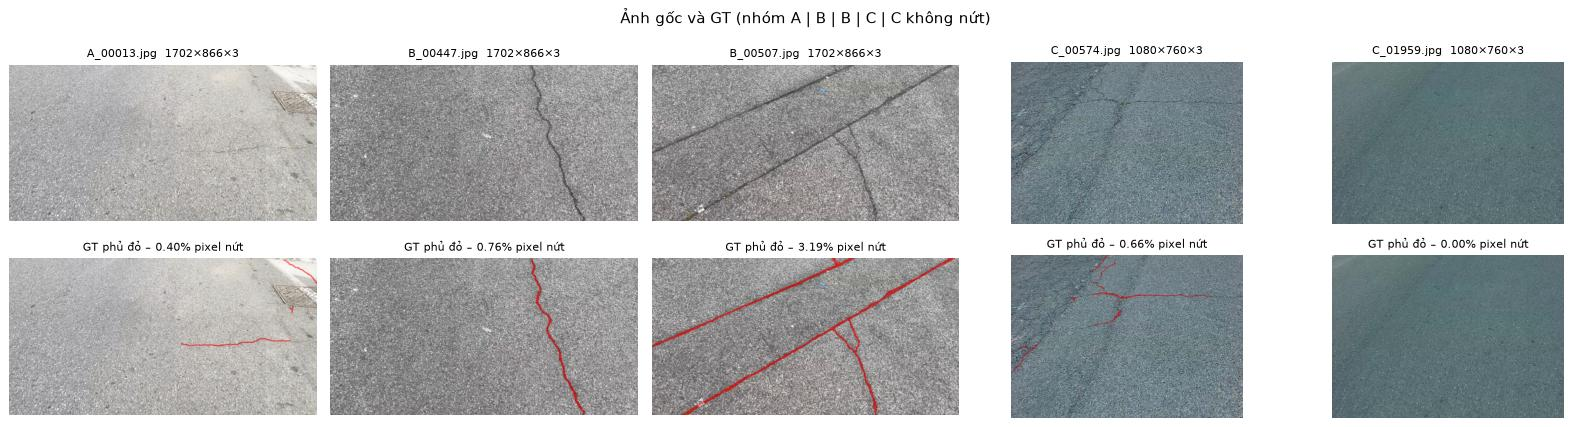

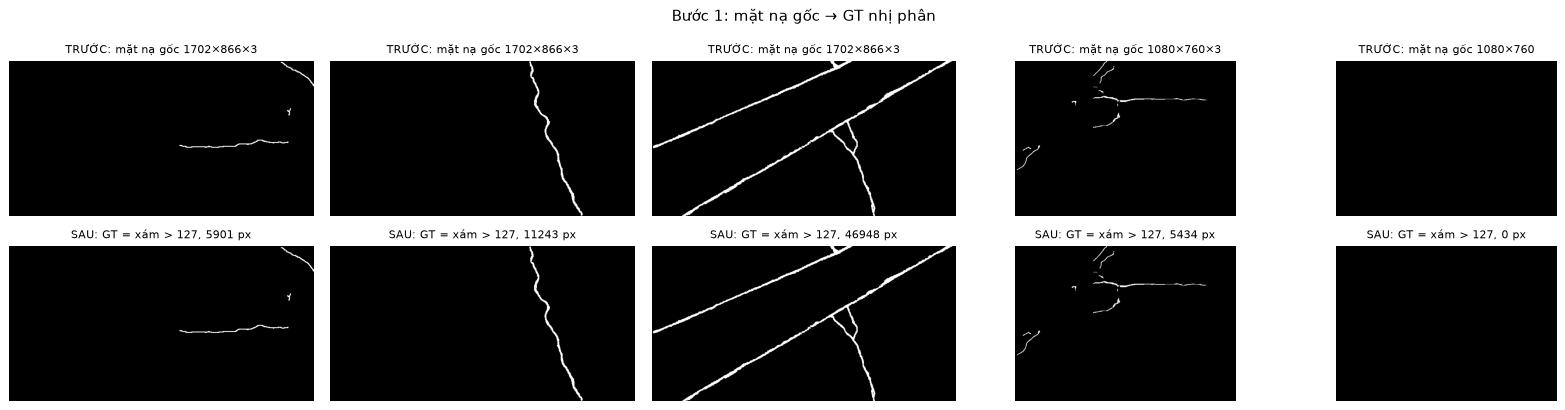

In [4]:
r_ = np.random.default_rng(SEED)
empty_train = {sid for sid, e in zip(TRAIN_IDS, INFO[INFO["tập"] == "train"]["rỗng"]) if e}   # INFO giữ đúng thứ tự TRAIN_IDS
pick = lambda g, n, empty: list(r_.choice(sorted(s for s in TUNE_IDS if s[0] == g and (s in empty_train) == empty), n, replace=False))
SAMPLE_IDS = pick("A", 1, False) + pick("B", 2, False) + pick("C", 1, False) + pick("C", 1, True)
S_IMG, S_GT = zip(*[read_pair("train", i) for i in SAMPLE_IDS])
S_RAWMASK = [read_mask_raw("train", i) for i in SAMPLE_IDS]
fig, ax = plt.subplots(2, 5, figsize=(18, 4.8))
for j in range(5):
    ax[0, j].imshow(rgb(small(S_IMG[j]))); ax[0, j].set_title(f"{SAMPLE_IDS[j]}.jpg  {shp(S_IMG[j])}")
    ax[1, j].imshow(rgb(small(overlay_red(S_IMG[j], S_GT[j])))); ax[1, j].set_title(f"GT phủ đỏ – {S_GT[j].mean()*100:.2f}% pixel nứt")
    for a in ax[:, j]: a.axis("off")
fig.suptitle("Ảnh gốc và GT (nhóm A | B | B | C | C không nứt)", fontsize=12); plt.tight_layout(); plt.show()

show_before_after([small(m if m.ndim == 2 else m[..., :3], nearest=True) for m in S_RAWMASK], [small(u8(g), nearest=True) for g in S_GT],
                  [f"mặt nạ gốc {shp(m)}" for m in S_RAWMASK], [f"GT = xám > 127, {g.sum()} px" for g in S_GT],
                  "Bước 1: mặt nạ gốc → GT nhị phân")

---
# Độ đo (dùng chung cho kiểm chứng, chọn tham số và đánh giá)

Tính trên **từng pixel** của mỗi ảnh, ở **kích thước gốc**, so với GT nhị phân:

$$\text{Dice} = \frac{2TP}{2TP+FP+FN},\quad \text{IoU} = \frac{TP}{TP+FP+FN},\quad \text{Precision} = \frac{TP}{TP+FP},\quad \text{Recall} = \frac{TP}{TP+FN}$$

| | |
|---|---|
| **Tại sao Dice và IoU** | Chỉ đếm TP, FP, FN, **bỏ qua TN** (khoảng 99% pixel nền), nên không bị lớp nền lấn át như accuracy. Dice chính là F1 mức pixel; IoU = Dice / (2 − Dice) nên IoU ≤ Dice |
| **Ảnh không nứt (GT rỗng)** | Dự đoán **rỗng** thì TP = FP = FN = 0, quy ước **Dice = IoU = 1**. Dự đoán **có pixel** thì **Dice = IoU = 0**. Precision, Recall chỉ tính trên **ảnh có nứt** (ảnh có nứt mà dự đoán rỗng thì P = R = 0) |
| **Báo cáo thêm** | **Dice ảnh nứt**: chỉ tính trên ảnh có nứt, không bị ảnh rỗng "kéo lên". **Dice/IoU gộp**: cộng dồn TP, FP, FN của mọi ảnh rồi mới tính. **Phát hiện mức ảnh**: số ảnh rỗng được trả rỗng đúng, số ảnh nứt bị trả rỗng |

In [5]:
def scores(pred, gt):
    tp = int(np.count_nonzero(pred & gt)); fp = int(np.count_nonzero(pred & ~gt)); fn = int(np.count_nonzero(~pred & gt))
    gpos, ppos = bool(gt.any()), bool(pred.any())
    return dict(tp=tp, fp=fp, fn=fn, gt_pos=gpos, pred_pos=ppos,
                dice=2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 1.0,
                iou=tp / (tp + fp + fn) if tp + fp + fn else 1.0,
                precision=(tp / (tp + fp) if tp + fp else 0.0) if gpos else np.nan,
                recall=tp / (tp + fn) if gpos else np.nan)

def summarize(df, by):
    g = df.groupby(by, sort=False); s = g[["tp", "fp", "fn"]].sum()
    pos = df[df.gt_pos].groupby(by, sort=False)
    return pd.DataFrame({
        "số ảnh": g.size(),
        "Dice": g.dice.mean(), "IoU": g.iou.mean(),
        "Dice ảnh nứt": pos.dice.mean(), "IoU ảnh nứt": pos.iou.mean(),
        "Precision": pos.precision.mean(), "Recall": pos.recall.mean(),
        "Dice gộp": 2 * s.tp / (2 * s.tp + s.fp + s.fn), "IoU gộp": s.tp / (s.tp + s.fp + s.fn),
        "ảnh rỗng đoán đúng": df[~df.gt_pos].groupby(by, sort=False).pred_pos.apply(lambda x: f"{(~x).sum()}/{len(x)}"),
        "ảnh nứt bị trả rỗng": pos.pred_pos.apply(lambda x: int((~x).sum())),
    })

---
# Bước 2 – Tiền xử lý (Chương 2, 3, 4)

## 2.0 Thu nhỏ ảnh: cạnh dài = 640 px (Chương 2: lấy mẫu)

| | |
|---|---|
| **Dùng gì** | Đổi kích thước sao cho **cạnh dài = 640 px**, giữ tỉ lệ khung hình (1702×866 → 640×326; 1080×760 → 640×450), nội suy **INTER_AREA**. Mặt nạ kết quả được phóng về **kích thước gốc** bằng **láng giềng gần nhất** trước khi so với GT |
| **Tại sao thu nhỏ** | (1) Ở kích thước gốc, vết nứt rộng 7–12 px và ảnh có rất nhiều chi tiết sỏi. Các bước sau dùng cửa sổ cố định (trung vị, nền, phép đóng, a_min), nên cần đưa vết nứt về bề rộng **ổn định, nhỏ** so với cửa sổ: khoảng 3–5 px ở 640 px (bảng dưới). (2) Số pixel giảm 4–7 lần, nên thử được hàng nghìn cấu hình tham số |
| **Tại sao INTER_AREA** | Khi **giảm** tần số lấy mẫu, mỗi pixel mới là **trung bình vùng** pixel cũ mà nó phủ, tức là lọc thông thấp trước khi lấy mẫu lại, nên tránh răng cưa (aliasing). Láng giềng gần nhất bỏ qua hàng và cột nên làm vết nứt mảnh bị đứt |
| **Tại sao phóng mặt nạ bằng láng giềng gần nhất** | Mặt nạ là **nhị phân**; nội suy tuyến tính sẽ sinh giá trị trung gian. Đánh giá luôn ở kích thước gốc với GT gốc |
| **Phương án khác** (bảng K1) | Dice tune: **kích thước gốc 0.225** (vết nứt quá rộng so với các cửa sổ, 101/250 ảnh nứt bị mất), 480 px 0.301, 800 px 0.305, **640 px 0.324** |
| **Tham số chọn: 640** | Tốt nhất ở K1. Trong lưới thử {480, 640}, cấu hình 640 px cũng cho **Dice val cao nhất** |

```
1702×866  ──INTER_AREA──►  640×326       mỗi pixel mới ≈ trung bình khối 2.66×2.66 pixel cũ
vết nứt rộng 12 px      ──►  ≈ 4.5 px
```

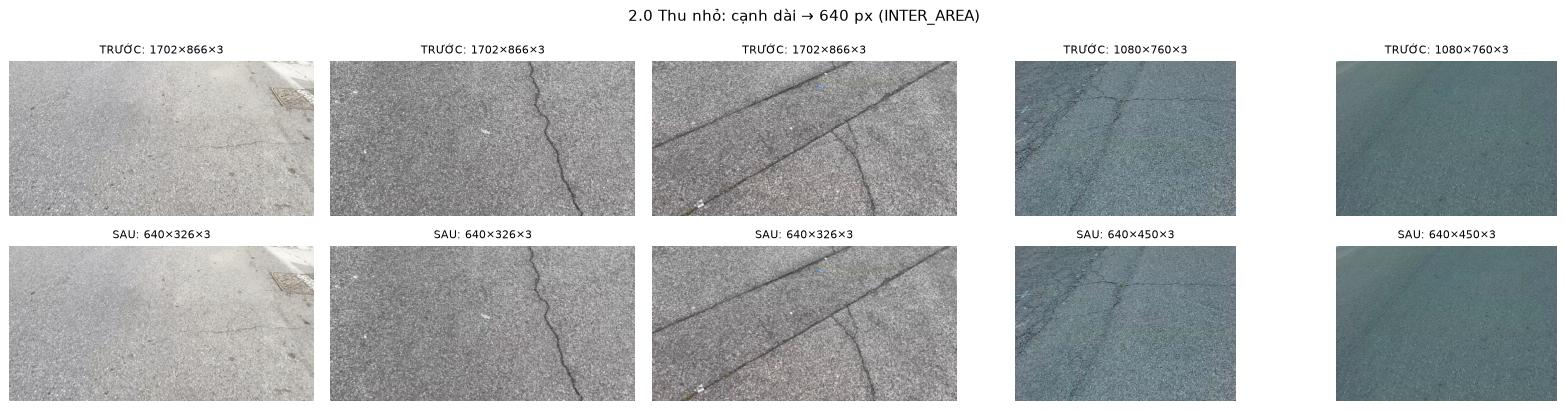

bề rộng GT (px),480,640,gốc
nhóm,,,
A,2.4,3.2,8.4
B,3.5,4.7,12.1
C,3.4,4.5,7.4


In [6]:
def resize_long(img, size, interp=cv2.INTER_AREA):
    h, w = img.shape[:2]; s = size / max(h, w)
    return cv2.resize(img, (round(w * s), round(h * s)), interpolation=interp)

def to_orig(mask, shape):
    return cv2.resize(mask.astype(np.uint8), (shape[1], shape[0]), interpolation=cv2.INTER_NEAREST) > 0

S_SMALL = [resize_long(x, P["size"]) for x in S_IMG]
show_before_after(S_IMG, S_SMALL, [shp(x) for x in S_IMG], [shp(x) for x in S_SMALL],
                  f"2.0 Thu nhỏ: cạnh dài → {P['size']} px (INTER_AREA)")

# Bề rộng vết nứt GT (≈ diện tích / độ dài khung xương) – các ảnh tune có vết nứt
def gt_width(a):
    sid, size = a
    gt = read_pair("train", sid)[1]
    if size: gt = resize_long(gt.astype(np.uint8) * 255, size) > 127
    sk = skeletonize(gt).sum()
    return dict(nhóm=sid[0], size=size or "gốc", w=gt.sum() / sk if sk else np.nan)
W = pd.DataFrame(pmap(gt_width, [(s, z) for s in TUNE_IDS for z in (None, 480, 640)]))
display(W.pivot_table(index="nhóm", columns="size", values="w", aggfunc="mean").round(1).rename_axis(columns="bề rộng GT (px)"))

## 2.1 Chuyển ảnh xám (Chương 4: hệ màu)

| | |
|---|---|
| **Dùng gì** | **Y = 0.299R + 0.587G + 0.114B** (`cv2.COLOR_BGR2GRAY`): 3 kênh màu → 1 kênh cường độ |
| **Tại sao** | Vết nứt khác nền ở **độ sáng** (khe hở ít nhận ánh sáng nên tối hơn), **không khác về màu**: mặt đường và vết nứt cùng tông xám. Phần có màu nổi bật trong ảnh là **vạch sơn, cỏ, vỉa hè**, không phải vết nứt |
| **Phương án khác** | Kênh H của HSV: gần như vô nghĩa với ảnh ít màu. Xử lý cả 3 kênh: tốn gấp 3 lần mà không thêm thông tin về vết nứt |
| **Tham số** | Không có; hệ số cố định theo chuẩn ITU-R BT.601 (mô phỏng độ nhạy của mắt, kênh G có trọng số lớn nhất) |

Ví dụ: (R, G, B) = (120, 110, 100) → Y = 35.88 + 64.57 + 11.40 = 111.85 ≈ **112**.

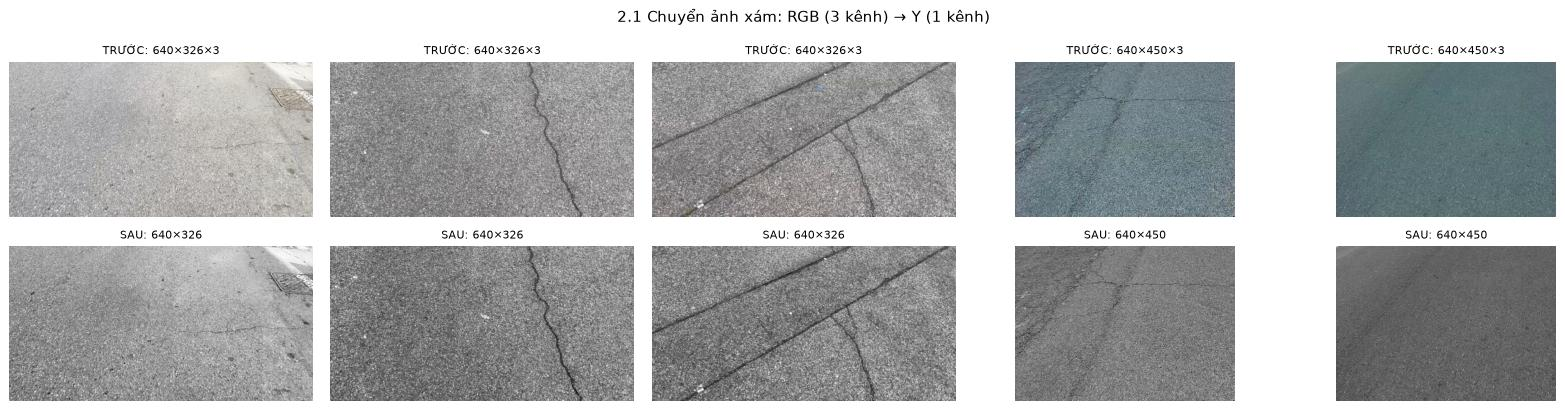

In [7]:
def to_gray(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

S_GRAY = [to_gray(x) for x in S_SMALL]
show_before_after(S_SMALL, S_GRAY, [shp(x) for x in S_SMALL], [shp(x) for x in S_GRAY],
                  "2.1 Chuyển ảnh xám: RGB (3 kênh) → Y (1 kênh)")

## 2.2 Khử nhiễu bằng lọc trung vị 5×5 (Chương 3)

| | |
|---|---|
| **Dùng gì** | Lọc trung vị k×k (`cv2.medianBlur`): mỗi pixel được thay bằng trung vị của k² pixel lân cận |
| **Tại sao trung vị** | Nhiễu trên mặt đường chủ yếu là **hạt sỏi** nhỏ, sáng tối xen kẽ, có tính chất giống **nhiễu muối tiêu**. Theo Ch3, trung vị là bộ lọc phù hợp nhất cho loại nhiễu này: đốm nhỏ hơn nửa cửa sổ bị xóa hẳn, còn **biên** của vùng lớn (bờ vết nứt) được **giữ sắc** |
| **Phương án khác** (bảng K3) | **Không lọc**: hạt sỏi lọt qua ngưỡng, Dice tune chỉ 0.224. **Trung vị 3×3**: 0.291. **Gauss 5×5**: 0.316, gần bằng trung vị 5×5 (0.324). Gauss còn bắt vết nứt tốt hơn một chút (Dice ảnh nứt 0.303 so với 0.273), nhưng vì Gauss chỉ **làm mờ** chứ không **xóa** đốm sỏi, các đốm mờ còn sót tạo thêm báo nhầm: chỉ 19/50 ảnh lành được trả rỗng, trung vị được 29/50. Tổng thể trung vị tốt hơn |
| **Tham số chọn: 5×5** (thử 3, 5) | Sau 2.0, vết nứt rộng 3–5 px. Với nét rộng 3 px, cửa sổ 5×5 có 15/25 pixel tối nên trung vị vẫn tối: **vết nứt được giữ**. Đốm sỏi 2×2 chỉ có 4/25 pixel tối nên **bị xóa**. Cửa sổ 3×3 khử nhiễu yếu hơn, đặc biệt với nền sỏi thô của nhóm B. Từ 7×7 trở lên sẽ xóa luôn vết nứt mảnh (≤ 3 px) nên không thử |

```
Đốm sỏi 2×2, cửa sổ 5×5:            Vết nứt rộng 3 px, cửa sổ 5×5:
120 120 120 120 120                  120  60  60  60 120
120  30  30 120 120                  120  60  60  60 120
120  30  30 120 120  → 120 (XÓA)     120  60  60  60 120   → 60 (GIỮ: 15/25 pixel tối)
120 120 120 120 120                  120  60  60  60 120
120 120 120 120 120                  120  60  60  60 120
```

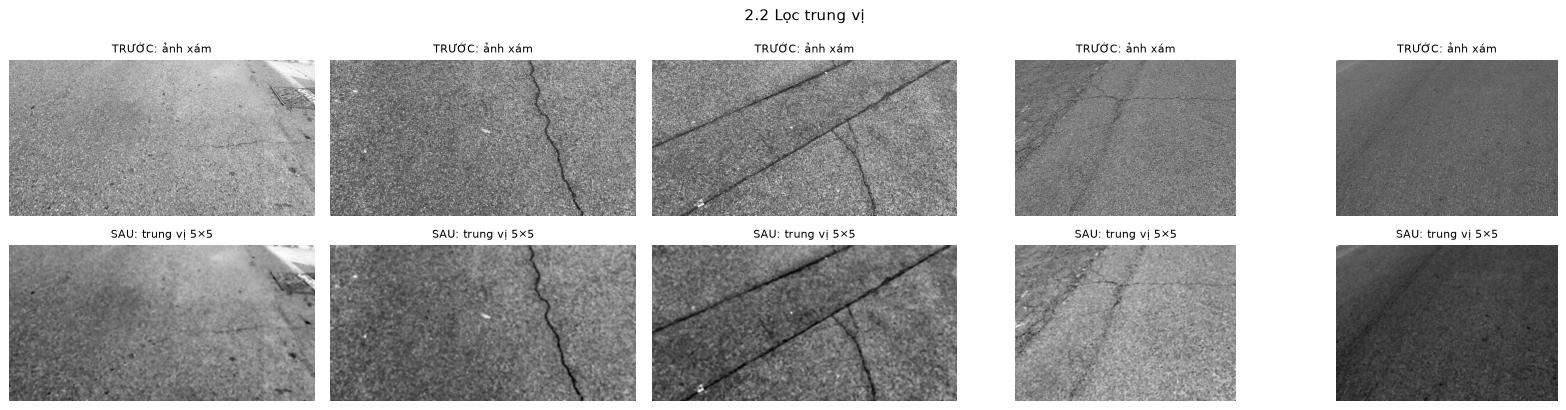

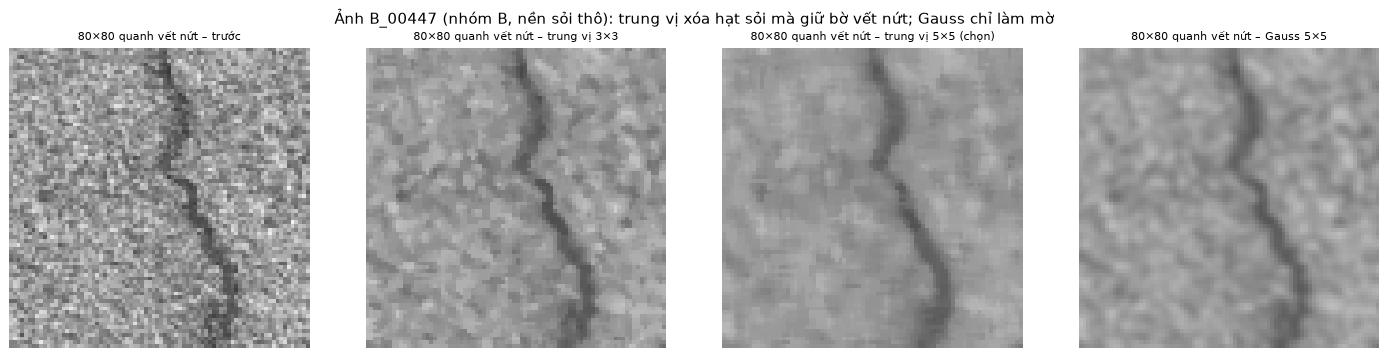

In [8]:
def denoise(gray, p):
    k = p["median"]
    if p.get("denoise", "median") == "gauss":
        return cv2.GaussianBlur(gray, (k, k), 0)
    return cv2.medianBlur(gray, k) if k > 1 else gray

S_MED = [denoise(g, P) for g in S_GRAY]
show_before_after(S_GRAY, S_MED, ["ảnh xám"] * 5, [f"trung vị {P['median']}×{P['median']}"] * 5, "2.2 Lọc trung vị")
j = 1; y, x = np.argwhere(resize_long(u8(S_GT[j]), P["size"]) > 127)[0]
y, x = max(0, y - 40), max(0, x - 40)
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, (t, im) in zip(ax, [("trước", S_GRAY[j]), ("trung vị 3×3", cv2.medianBlur(S_GRAY[j], 3)),
                           ("trung vị 5×5 (chọn)", cv2.medianBlur(S_GRAY[j], 5)), ("Gauss 5×5", cv2.GaussianBlur(S_GRAY[j], (5, 5), 0))]):
    a.imshow(im[y:y+80, x:x+80], cmap="gray", vmin=0, vmax=255); a.set_title(f"80×80 quanh vết nứt – {t}"); a.axis("off")
plt.suptitle(f"Ảnh {SAMPLE_IDS[j]} (nhóm B, nền sỏi thô): trung vị xóa hạt sỏi mà giữ bờ vết nứt; Gauss chỉ làm mờ"); plt.tight_layout(); plt.show()

## 2.3 Bù chiếu sáng: ảnh tỉ số R = 128·I/B (Chương 3)

| | |
|---|---|
| **Dùng gì** | (1) Ước lượng **ảnh nền** B = lọc trung vị cửa sổ **lớn** bg×bg. (2) **R = 128·I/(B + 1)**, cắt về [0, 255]. Ảnh chuyển từ cường độ **tuyệt đối** sang cường độ **tương đối so với nền**: nền ≈ 128, vết nứt < 128 |
| **Tại sao cần** | Ảnh có bóng đổ, và ảnh chụp xiên (nhóm A, C) tối dần theo khoảng cách. Một ngưỡng chung trên I sẽ gán nhầm cả vùng bóng là vết nứt và bỏ sót vết nứt ở vùng sáng |
| **Tại sao trung vị cửa sổ lớn làm nền** | Vết nứt rất mảnh so với cửa sổ nên chiếm ít pixel trong cửa sổ, và trung vị **bỏ qua** chúng: B chính là **mức xám nền cục bộ**. Bóng đổ thay đổi **chậm** nên nằm trong B |
| **Tại sao dùng phép chia** | Ánh sáng tác động theo kiểu **nhân**: I = phản xạ × chiếu sáng. Chia cho B triệt tiêu thành phần chiếu sáng, nên vết nứt trong bóng và ngoài nắng có **cùng tỉ lệ** tối so với nền. Phép trừ (I − B) thì vết nứt trong bóng có độ chênh nhỏ hơn |
| **Phương án khác** (bảng K4) | **Không bù sáng**: Dice tune 0.256, Dice ảnh nứt chỉ 0.163, 135/250 ảnh nứt bị mất. **Nền bằng phép đóng hình thái 21×21** (Ch7): 0.286. Phép đóng lấy **cực đại** cục bộ trước nên nền bị nâng theo các hạt sỏi sáng. **Phép trừ** R = 128 + I − B: 0.325, **tương đương** phép chia (0.324). Sau khi thu nhỏ và khử nhiễu, độ sáng nền trong mỗi ảnh không chênh nhau quá lớn nên hai cách cho kết quả gần như nhau. Giữ phép chia vì nó đúng với mô hình chiếu sáng kiểu nhân (ví dụ dưới) |
| **Tham số chọn: 71×71** (thử 31, 51, 71) | Cửa sổ phải **lớn hơn nhiều so với bề rộng vết nứt** (3–5 px) để vết nứt không lọt vào B, và nhỏ hơn vệt bóng để theo kịp thay đổi chiếu sáng. Ba giá trị cho Dice tune gần nhau (chênh ≤ 0.009); 71 cho Dice val cao nhất |

```
vị trí    :   0    1    2    3    4    5    6    7    8    9   10
              ── nắng ──────────►  chuyển dần  ──── bóng râm ────
I (xám)   : 160  160  [96] 160  150  130  110  100  [60] 100  100
B (nền)   : 160  160  160  160  150  130  110  100  100  100  100
R=128·I/B : 127  127  [76] 127  127  127  126  126  [76] 126  126   ← chia: hai vết nứt như nhau
128+I−B   : 128  128  [64] 128  128  128  128  128  [88] 128  128   ← trừ: vết nứt trong bóng nhạt hơn
→ Ngưỡng trên I (I < 105) gán nhầm cả vùng bóng (7, 9, 10). Trên R, một ngưỡng duy nhất là đủ.
```

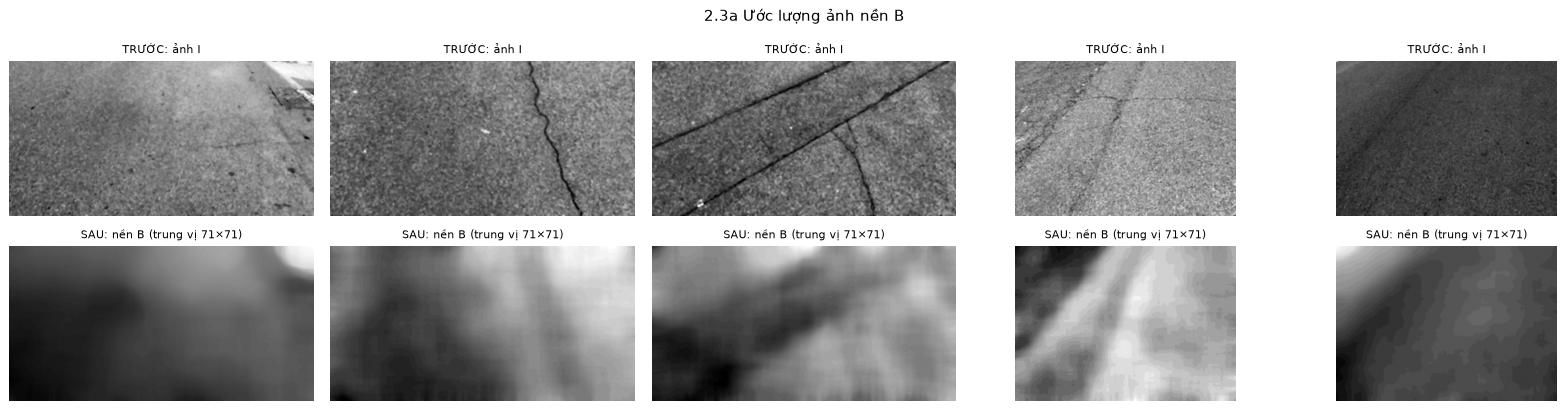

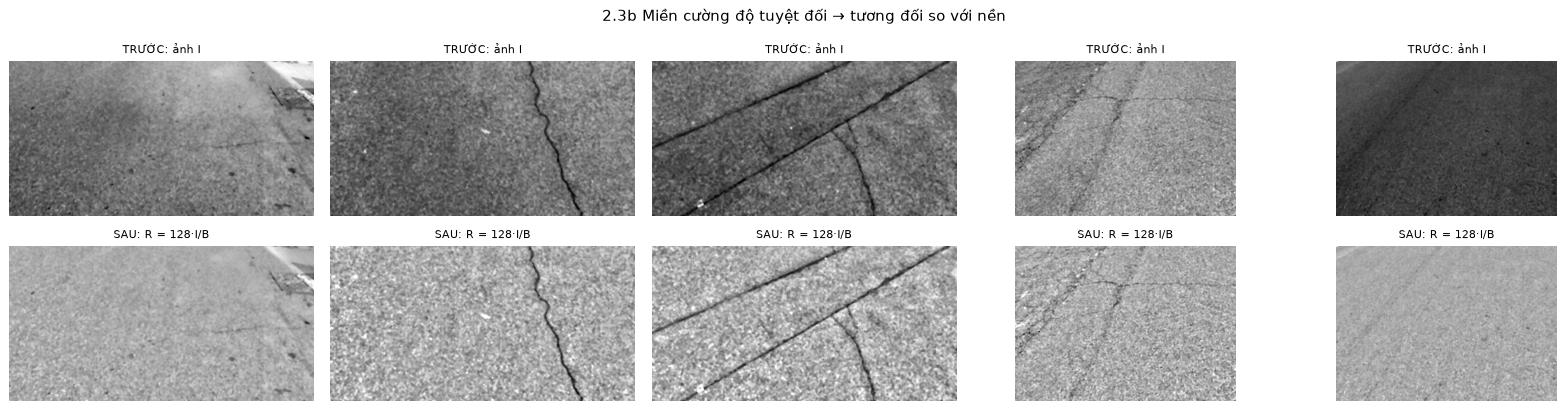

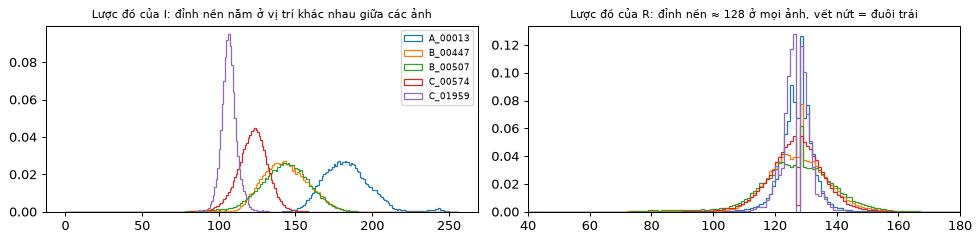

In [9]:
def illumination_ratio(img, k, mode="median", op="div"):
    bg = cv2.medianBlur(img, k) if mode == "median" else cv2.morphologyEx(img, cv2.MORPH_CLOSE, ellipse(k))
    I, B = img.astype(np.float32), bg.astype(np.float32)
    R = 128.0 + I - B if op == "sub" else 128.0 * I / (B + 1.0)
    return np.clip(R, 0, 255).astype(np.uint8), bg

S_RATIO, S_BG = zip(*[illumination_ratio(m, P["bg"]) for m in S_MED])
show_before_after(S_MED, S_BG, ["ảnh I"] * 5, [f"nền B (trung vị {P['bg']}×{P['bg']})"] * 5, "2.3a Ước lượng ảnh nền B")
show_before_after(S_MED, S_RATIO, ["ảnh I"] * 5, ["R = 128·I/B"] * 5,
                  "2.3b Miền cường độ tuyệt đối → tương đối so với nền", vmin_a=60, vmax_a=160)
fig, ax = plt.subplots(1, 2, figsize=(11, 2.8))
for j in range(5):
    ax[0].hist(S_MED[j].ravel(), 256, range=(0, 256), histtype="step", density=True, label=SAMPLE_IDS[j])
    ax[1].hist(S_RATIO[j].ravel(), 256, range=(0, 256), histtype="step", density=True, label=SAMPLE_IDS[j])
ax[0].set_title("Lược đồ của I: đỉnh nền nằm ở vị trí khác nhau giữa các ảnh")
ax[1].set_title("Lược đồ của R: đỉnh nền ≈ 128 ở mọi ảnh, vết nứt = đuôi trái")
ax[1].set_xlim(40, 180); ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

---
# Bước 3 – Xử lý chính (Chương 5, 7)

**Ý tưởng:** vết nứt là vùng **tối hơn nền** (điều kiện D) và **có biên sắc** (điều kiện E). Pixel vết nứt phải thỏa **cả hai**.

## 3.1 Làm trơn lược đồ của R (Chương 5, tr.62)

| | |
|---|---|
| **Dùng gì** | Làm trơn lược đồ h[b] bằng **trung bình trượt cửa sổ W**: h'[b] = (1/W)·Σ h[b+k], k từ −W/2 đến W/2. Không làm dịch vị trí đỉnh |
| **Tại sao** | Giáo trình nêu: các thuật toán tìm ngưỡng tự động thường làm trơn lược đồ trước để khử dao động nhỏ (W thường là 3 hoặc 5). R = 128·I/B được tính từ số nguyên rồi làm tròn (lượng tử hóa, Ch2), nên một số mức nhận nhiều pixel hơn hẳn mức kế bên: lược đồ có **răng cưa**, đặc biệt là **gai ở 128 cạnh hố ở 127**. Thuật toán tam giác (3.2) tìm điểm xa đường Δ nhất nên rất dễ "rơi" vào một hố như vậy |
| **Phương án khác** (bảng K5) | Không làm trơn (W = 1): Dice tune 0.303 so với 0.324 khi W = 3 |
| **Tham số chọn: W = 3** (thử 3, 5) | Cửa sổ nhỏ nhất khử được răng cưa một mức; W = 5 làm tù đuôi tối nên θ hơi lệch (Dice tune 0.317 so với 0.328) |

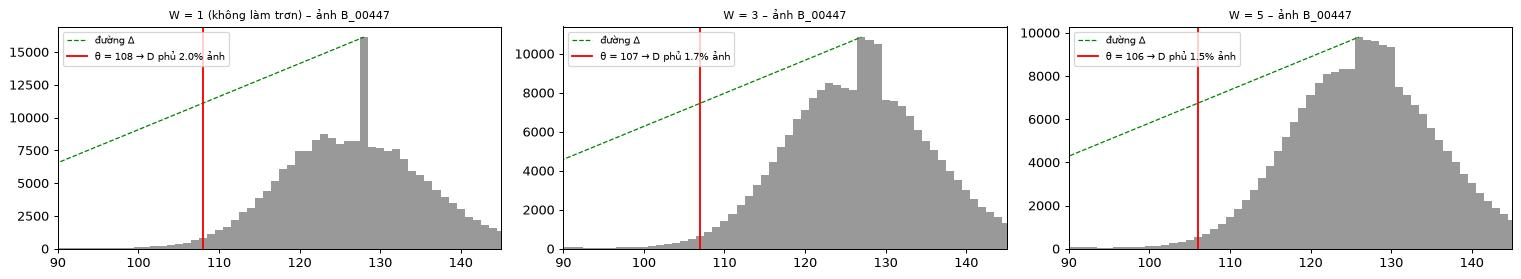

In [10]:
def histogram(img, w=1):
    """Lược đồ xám, làm trơn bằng trung bình trượt cửa sổ w (Ch5 tr.62); w = 1: không làm trơn."""
    h = np.bincount(img.ravel(), minlength=256).astype(np.float64)
    if w > 1:
        h = np.convolve(np.pad(h, w // 2, mode="edge"), np.ones(w) / w, mode="valid")
    return h

def triangle_threshold(img, w=3):
    """3.2 – Zack: Δ nối (b_min, h[b_min]) – (b_max, h[b_max]); θ = b có khoảng cách tới Δ lớn nhất.
    Đuôi đối tượng nằm ở phía TỐI (mức thấp) của đỉnh nền."""
    h = histogram(img, w)
    bmax = int(np.argmax(h)); bmin = int(np.nonzero(h)[0][0])
    if bmax == bmin:
        return bmax
    b = np.arange(bmin, bmax + 1)
    x1, y1, x2, y2 = bmin, h[bmin], bmax, h[bmax]
    d = np.abs((y2 - y1) * b - (x2 - x1) * h[b] + x2 * y1 - y2 * x1) / np.hypot(y2 - y1, x2 - x1)
    return int(b[np.argmax(d)])

j = 1; r = S_RATIO[j]
fig, ax = plt.subplots(1, 3, figsize=(17, 3.2))
for a, w in zip(ax, (1, 3, 5)):
    hh = histogram(r, w); t = triangle_threshold(r, w); bmin = int(np.nonzero(hh)[0][0]); bmax = int(np.argmax(hh))
    a.bar(np.arange(256), hh, width=1, color="0.6"); a.plot([bmin, bmax], [hh[bmin], hh[bmax]], "g--", lw=1, label="đường Δ")
    a.axvline(t, color="red", label=f"θ = {t} → D phủ {np.mean(r < t)*100:.1f}% ảnh"); a.set_xlim(90, 145); a.legend(fontsize=8)
    a.set_title(f"W = {w}" + (" (không làm trơn)" if w == 1 else "") + f" – ảnh {SAMPLE_IDS[j]}")
plt.tight_layout(); plt.show()

## 3.2 Vùng tối hơn nền D: ngưỡng tam giác (Chương 5, tr.78)

| | |
|---|---|
| **Dùng gì** | Thuật toán tam giác của Zack trên lược đồ **đã làm trơn**: nối đỉnh lược đồ (b_max) với mức khác 0 xa nhất về phía tối (b_min) bằng đường Δ; **θ = b có khoảng cách tới Δ lớn nhất**. Gán **D = (R < θ)**: ảnh xám → ảnh nhị phân |
| **Tại sao tam giác** | Sau 2.3, lược đồ R có **một đỉnh rất lớn** (nền, khoảng 99%) và **đuôi mỏng** về phía tối (vết nứt, khoảng 1%). Đây đúng là dạng lược đồ mà phương pháp tam giác được thiết kế cho: θ rơi vào "chỗ gãy" nơi đuôi tách khỏi đỉnh nền. θ được tính **tự động cho từng ảnh**, nên tự thích nghi với độ tương phản của mỗi ảnh |
| **Phương án khác** | **Otsu** giả định lược đồ có **hai đỉnh** và cực đại phương sai giữa hai lớp. Khi một lớp chỉ chiếm 1%, phương sai bị lớp nền chi phối, nên Otsu đặt ngưỡng vào **giữa đỉnh nền** và gán gần một nửa ảnh là vết nứt (hình dưới). Thay tam giác bằng Otsu thì Dice tune giảm từ 0.324 xuống **0.082** (bảng K6). **Ngưỡng cố định**: không thích nghi được với độ tương phản của từng ảnh |
| **Tham số** | Không có; θ tự động |

```
 h │                 █ ← b_max (nền)
   │                ██
   │               ███
   │  Δ        . ' ███
   │     . '   ↕d max ███
   │. '  ▂▃▄▅▆▇█████████▇▅▃
   └──┬──────────┬────┬──── b
    b_min        θ   128
```

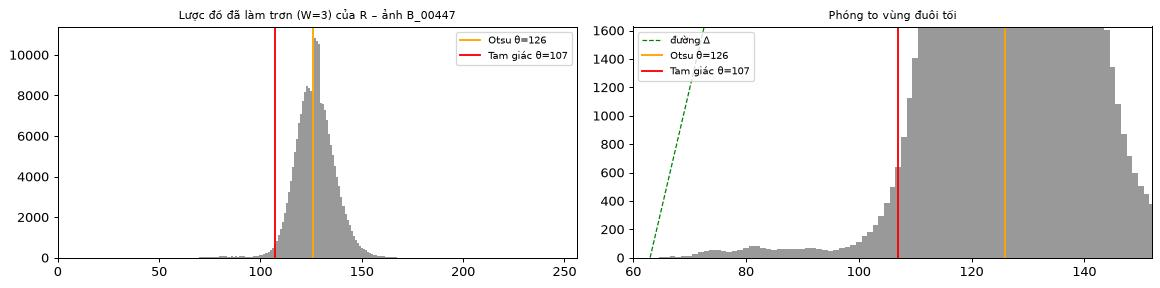

Tỉ lệ pixel bị gán là nứt: Otsu 43.9% | tam giác 1.7% | GT 0.8%


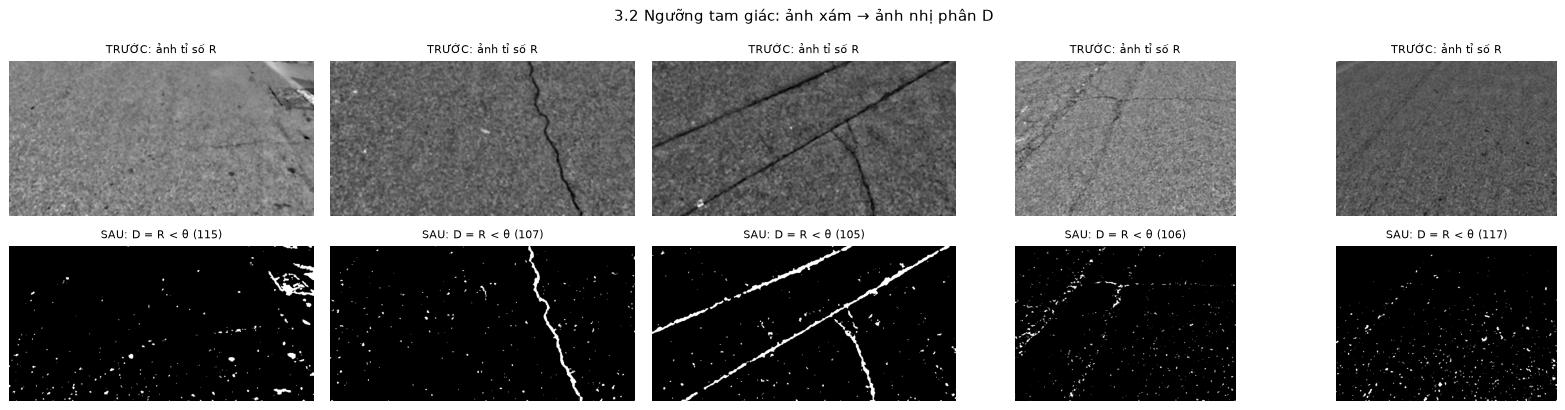

In [11]:
def dark_region(ratio, w=3):
    t = triangle_threshold(ratio, w)
    return ratio < t, t

j = 1; r = S_RATIO[j]
h = histogram(r, P["hist_w"])
t_tri = triangle_threshold(r, P["hist_w"]); t_otsu, _ = cv2.threshold(r, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
bmin, bmax = int(np.nonzero(h)[0][0]), int(np.argmax(h))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.3))
for k, lim in enumerate([(0, 256), (bmin - 3, bmax + 25)]):
    ax[k].bar(np.arange(256), h, width=1, color="0.6")
    if k == 1: ax[k].plot([bmin, bmax], [h[bmin], h[bmax]], "g--", lw=1, label="đường Δ")
    ax[k].axvline(t_otsu, color="orange", lw=1.5, label=f"Otsu θ={t_otsu:.0f}")
    ax[k].axvline(t_tri, color="red", lw=1.5, label=f"Tam giác θ={t_tri}")
    ax[k].set_xlim(*lim); ax[k].legend(fontsize=8)
ax[0].set_title(f"Lược đồ đã làm trơn (W={P['hist_w']}) của R – ảnh {SAMPLE_IDS[j]}"); ax[1].set_title("Phóng to vùng đuôi tối"); ax[1].set_ylim(0, h[bmax] * 0.15)
plt.tight_layout(); plt.show()
gt_s = resize_long(u8(S_GT[j]), P["size"]) > 127
print(f"Tỉ lệ pixel bị gán là nứt: Otsu {np.mean(r < t_otsu)*100:.1f}% | tam giác {np.mean(r < t_tri)*100:.1f}% | GT {gt_s.mean()*100:.1f}%")

S_D, S_T = zip(*[dark_region(r, P["hist_w"]) for r in S_RATIO])
show_before_after(S_RATIO, [u8(m) for m in S_D], ["ảnh tỉ số R"] * 5, [f"D = R < θ ({t})" for t in S_T],
                  "3.2 Ngưỡng tam giác: ảnh xám → ảnh nhị phân D")

## 3.3 Vùng gần biên mạnh E: Sobel + Otsu + giãn (Chương 5, 7)

| | |
|---|---|
| **Dùng gì** | (1) Sobel 3×3 trên R, **\|∇R\| = \|Gx\| + \|Gy\|**, chuẩn hóa về [0, 255]. (2) **Otsu** trên \|∇R\| để lấy **biên mạnh**. (3) **Giãn** bằng phần tử **ellipse** để được E |
| **Tại sao dùng biên** | Vết nứt thật vừa **tối** vừa có **biên sắc** (chuyển đột ngột từ nền vào khe nứt). Vệt tối chuyển **từ từ** (vệt ẩm loang, vệt dầu lớn, bóng còn sót) vượt qua 3.2 nhưng phần lõi không có biên mạnh, nên E loại được |
| **Tại sao Sobel và \|Gx\| + \|Gy\|** | Sobel vừa lấy đạo hàm vừa làm trơn theo hướng vuông góc nên ít nhạy nhiễu hơn sai phân thường. \|Gx\| + \|Gy\| là xấp xỉ độ lớn gradient của Ch5: không cần căn bậc hai, thứ tự lớn nhỏ gần giống √(Gx² + Gy²) |
| **Tại sao Otsu ở đây** (khác 3.2) | Lược đồ \|∇R\| gồm **hai nhóm rõ hơn** (vùng phẳng và vùng biên, cả hai đều chiếm tỉ lệ đáng kể) nên giả định hai lớp của Otsu hợp lý |
| **Tại sao phải giãn** | Ngay **tại tâm** vết nứt, gradient **bằng 0**; biên chỉ nằm ở **hai bờ**. Phải giãn mới phủ được thân vết nứt. Ellipse đẳng hướng nên vết nứt theo hướng nào cũng như nhau |
| **Phương án khác** (bảng K7) | Bỏ điều kiện biên (M = D): Dice tune 0.296 so với 0.324. Điều kiện biên có lợi chủ yếu trên **ảnh lành** (29/50 ảnh được trả rỗng, so với 16/50 khi bỏ): nó xóa các vệt tối loang, nên tổng diện tích của ảnh lành nhỏ lại và bước 4.4 nhận ra được. Đổi lại, trên ảnh có nứt nó xóa nhầm một ít mép vết nứt (Dice ảnh nứt 0.273 so với 0.291) |
| **Tham số chọn: giãn 3×3** (thử 3, 5, 7) | Giãn **ít nhất** đủ phủ thân vết nứt rộng 3–5 px (hai bờ cách nhau 3–5 px, mỗi bờ giãn 1 px). Giãn nhiều (7×7) làm E phủ gần hết ảnh nên điều kiện biên mất tác dụng (Dice tune: 3×3 0.328, 5×5 0.320, 7×7 0.318) |

```
R:     128 128 128  80 128 128 128
Gx:      0   0 -192   0 192   0   0     → |∇R|: 0 0 192 0 192 0 0   (tâm nứt = 0!)
Otsu:    ·   ·   █   ·   █   ·   ·     giãn ─►  E:  · █ █ █ █ █ ·   (phủ kín thân vết nứt)
```

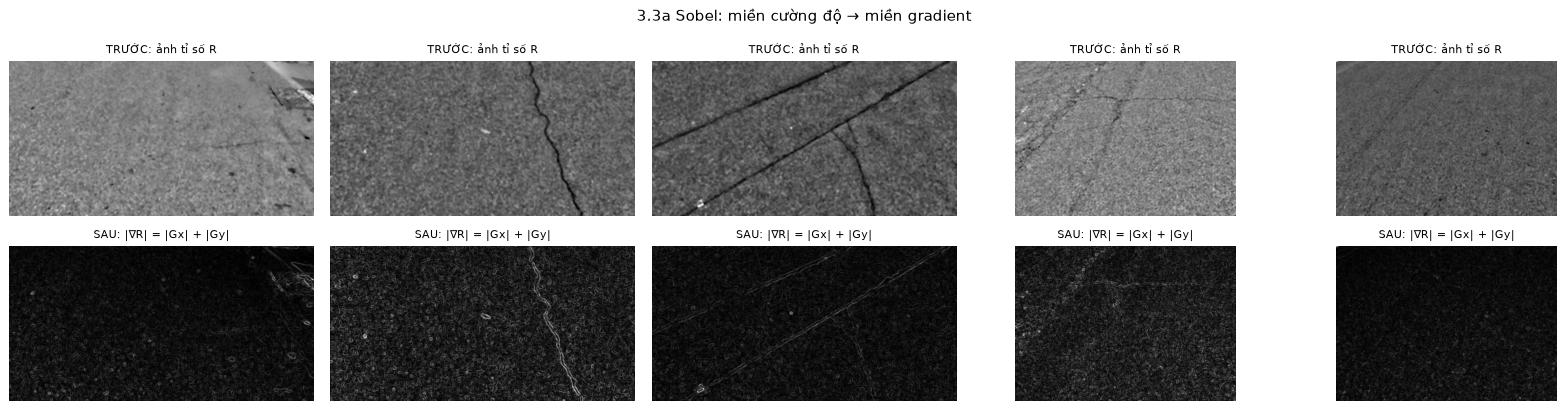

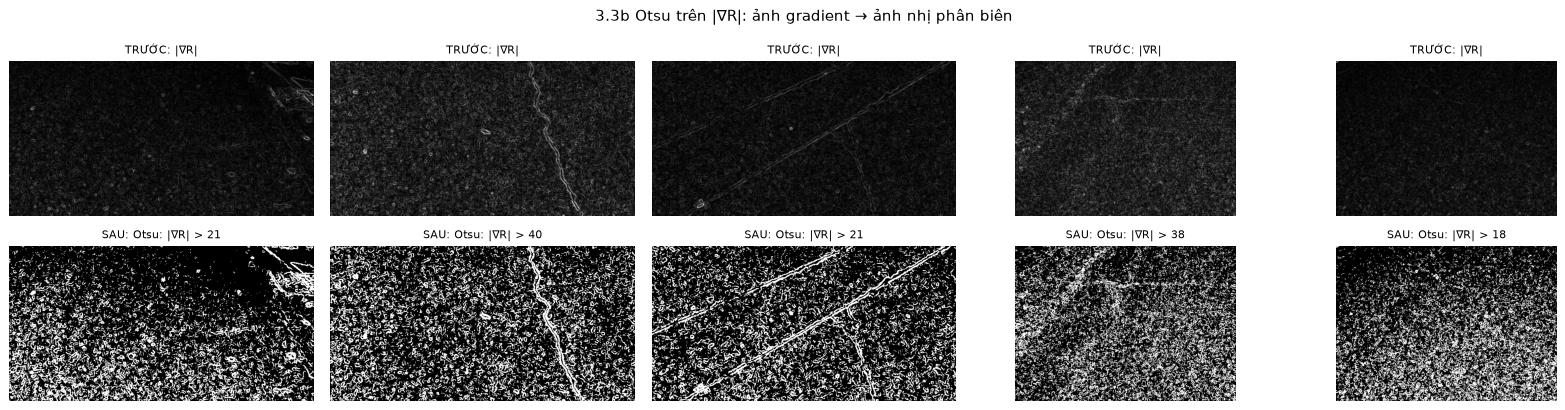

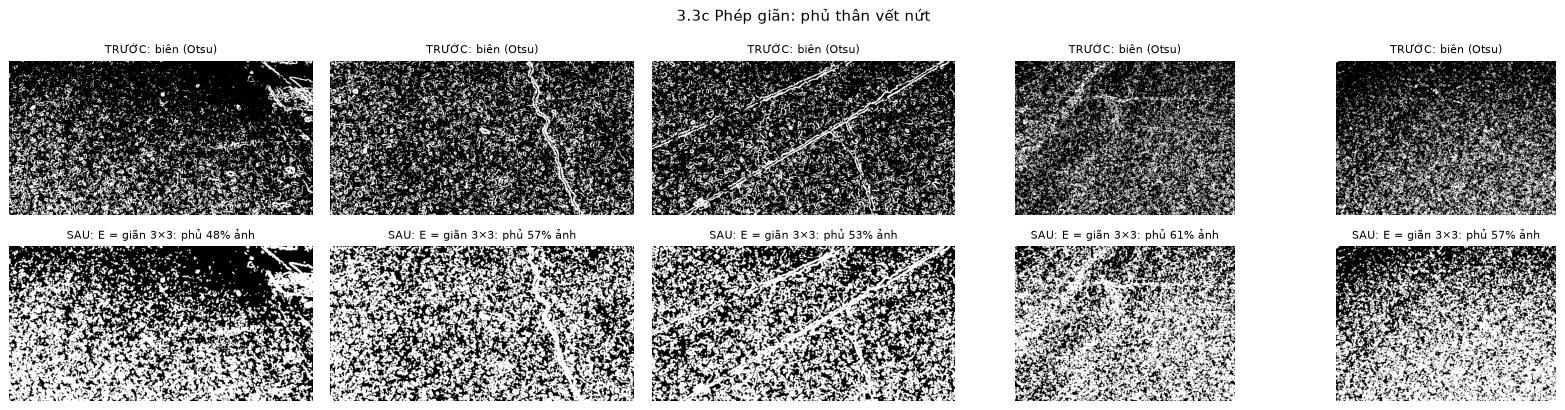

In [12]:
def sobel_l1(img):
    gx = cv2.Sobel(img, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(img, cv2.CV_32F, 0, 1, ksize=3)
    return cv2.normalize(np.abs(gx) + np.abs(gy), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

def edge_region(ratio, dil):
    g = sobel_l1(ratio)
    t, edge = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return cv2.dilate(edge, ellipse(dil)) > 0, g, edge > 0, t

S_E, S_G, S_EDGE, S_TE = zip(*[edge_region(r, P["dil"]) for r in S_RATIO])
show_before_after(S_RATIO, S_G, ["ảnh tỉ số R"] * 5, ["|∇R| = |Gx| + |Gy|"] * 5,
                  "3.3a Sobel: miền cường độ → miền gradient")
show_before_after(S_G, [u8(e) for e in S_EDGE], ["|∇R|"] * 5, [f"Otsu: |∇R| > {t:.0f}" for t in S_TE],
                  "3.3b Otsu trên |∇R|: ảnh gradient → ảnh nhị phân biên")
show_before_after([u8(e) for e in S_EDGE], [u8(e) for e in S_E], ["biên (Otsu)"] * 5,
                  [f"E = giãn {P['dil']}×{P['dil']}: phủ {e.mean()*100:.0f}% ảnh" for e in S_E],
                  "3.3c Phép giãn: phủ thân vết nứt")

## 3.4 Mặt nạ thô M = D ∩ E

| | |
|---|---|
| **Dùng gì** | Giao hai mặt nạ nhị phân: pixel là vết nứt khi **vừa tối hơn nền** (D) **vừa gần biên mạnh** (E) |
| **Tại sao giao** | D bắt hầu hết vết nứt nhưng lẫn mảng tối loang; E bắt mọi biên, kể cả biên hạt sỏi **sáng**. Mỗi điều kiện loại một kiểu nhiễu mà điều kiện kia không loại được. M luôn là **tập con của D**: bước này chỉ xóa, không thêm |
| **Tham số** | Không có |

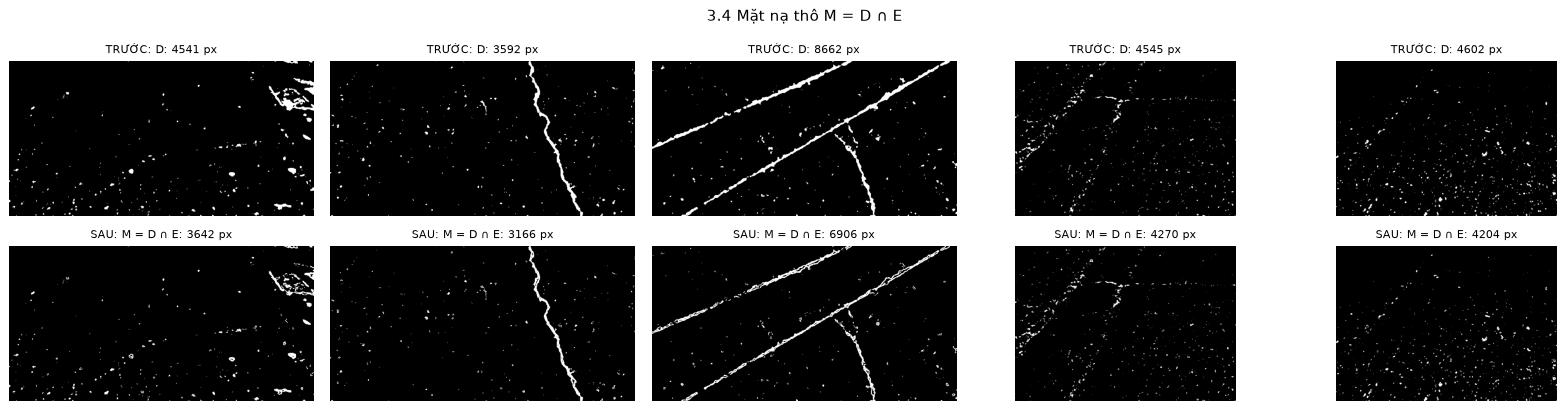

In [13]:
S_M = [d & e for d, e in zip(S_D, S_E)]
show_before_after([u8(d) for d in S_D], [u8(m) for m in S_M],
                  [f"D: {d.sum()} px" for d in S_D], [f"M = D ∩ E: {m.sum()} px" for m in S_M],
                  "3.4 Mặt nạ thô M = D ∩ E")

---
# Bước 4 – Hậu xử lý (Chương 7)

## 4.1 Phép đóng ellipse 7×7

| | |
|---|---|
| **Dùng gì** | Phép đóng **A • B = (A ⊕ B) ⊖ B** (giãn rồi co) với B là ellipse |
| **Tại sao đóng** | Sau bước 3, vết nứt bị **đứt thành nhiều đoạn** ở những chỗ hẹp hoặc sáng hơn. Phép đóng lấp các khe nhỏ hơn B và **nối** các đoạn lại; nhờ phép co ở sau, vết nứt **không bị dày lên vĩnh viễn** như khi chỉ giãn. Nối đoạn còn giúp bước 4.2 không xóa nhầm các mảnh nứt ngắn |
| **Phương án khác** (bảng K8) | **Phép mở** (co rồi giãn) xóa mọi chi tiết **mảnh hơn B**. Vết nứt chỉ rộng 3–5 px nên **mở 7×7 xóa sạch vết nứt** (Dice ảnh nứt = 0); mở 3×3 cho Dice tune 0.247. Việc xóa đốm nhỏ đã có 4.2 làm tốt hơn. **Không dùng phép hình thái**: 0.270, vì vết nứt rời rạc nên bị 4.2–4.3 xóa dần. Phép đóng 7×7: **0.324** |
| **Tham số chọn: 7×7** (thử 5, 7) | Khe đứt giữa các đoạn nứt thường vài pixel; 7×7 nối được khe tới khoảng 6 px. Dice tune 7×7 0.328, 5×5 0.317 |

```
Trước (2 vùng):                        Sau phép đóng (1 vùng):          Nếu dùng phép MỞ 7×7:
·███████···········                    ·███████···········              ···················
·███████·█████████·         ──►        ·█████████████████·              ···················   (vết nứt rộng
·········█████████·                    ·········█████████·              ···················    < 7 px bị xóa)
```

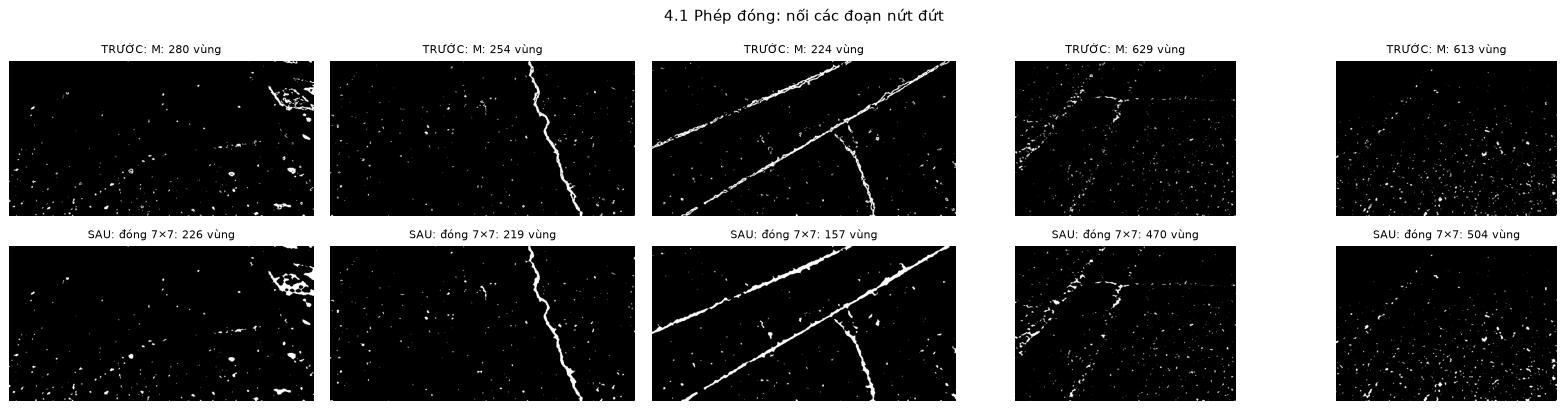

In [14]:
def closing(mask, k):
    return cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_CLOSE, ellipse(k)) > 0

def opening(mask, k):
    return cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_OPEN, ellipse(k)) > 0

S_C = [closing(m, P["close"]) for m in S_M]
show_before_after([u8(m) for m in S_M], [u8(m) for m in S_C],
                  [f"M: {ncc(m)} vùng" for m in S_M], [f"đóng {P['close']}×{P['close']}: {ncc(m)} vùng" for m in S_C],
                  "4.1 Phép đóng: nối các đoạn nứt đứt")

## 4.2 Lọc vùng theo diện tích (< 30 px)

| | |
|---|---|
| **Dùng gì** | Gán nhãn **thành phần liên thông 8-láng giềng** (`cv2.connectedComponentsWithStats`), **bỏ** vùng có diện tích **< a_min** |
| **Tại sao** | Sau phép đóng vẫn còn **đốm nhỏ** do hạt sỏi tối, lỗ nhỏ. Chúng rời rạc và có diện tích nhỏ, còn vết nứt là vùng **liên thông dài và lớn**. Dùng **8-láng giềng** để các pixel nối chéo của vết nứt xiên vẫn là một vùng |
| **Phương án khác** | Không lọc diện tích: Dice tune 0.307 so với 0.324 (bảng K9). Lọc mạnh hơn (60, 120 px): xem lưới tham số |
| **Tham số chọn: 30 px** (thử 30, 60, 120) | Với vết nứt rộng 3 px, 30 px tương ứng một đoạn dài khoảng 10 px: giữ được cả mảnh nứt ngắn. Lọc mạnh (120) xóa mất đoạn nứt (Dice tune 0.314). Việc quyết định "ảnh có nứt hay không" để cho 4.4 |

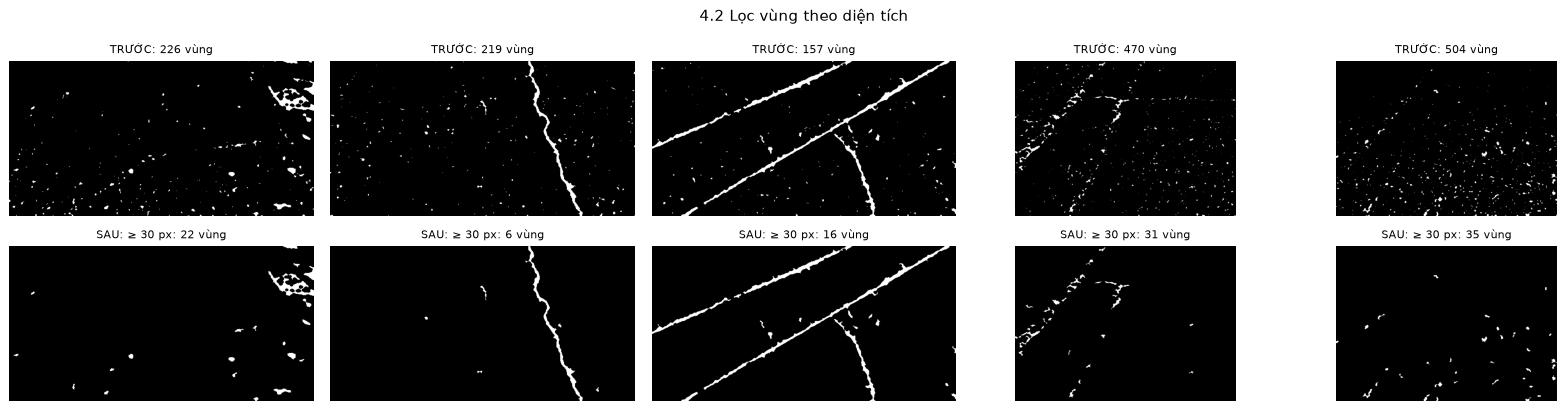

In [15]:
def area_filter(mask, a_min):
    n, lab, st, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    keep = st[:, cv2.CC_STAT_AREA] >= a_min
    keep[0] = False
    return keep[lab]

S_A = [area_filter(m, P["a_min"]) for m in S_C]
show_before_after([u8(m) for m in S_C], [u8(m) for m in S_A],
                  [f"{ncc(m)} vùng" for m in S_C], [f"≥ {P['a_min']} px: {ncc(m)} vùng" for m in S_A],
                  "4.2 Lọc vùng theo diện tích")

## 4.3 Lọc theo độ dãn: trục dài / trục ngắn của hộp chữ nhật xoay (L/S < 3 thì bỏ)

| | |
|---|---|
| **Dùng gì** | Với mỗi vùng, tìm **hộp chữ nhật xoay nhỏ nhất** bao vùng (`cv2.minAreaRect`), cạnh dài L, cạnh ngắn S (S ≥ 1 để nét 1 px không chia cho 0). **Độ dãn = L/S**. Bỏ vùng có **độ dãn < e_min** |
| **Tại sao** | Đây là đặc trưng **hình dạng** của Ch7 nắm đúng định nghĩa vết nứt: **dài và mảnh**, nên hộp bao rất dẹt (L ≫ S). Vết dầu, ổ gà, nắp cống, đốm tối lớn có diện tích đủ để qua 4.2 nhưng **gần tròn hoặc vuông** (L/S ≈ 1) |
| **Tại sao hộp xoay** | Hộp **xoay** theo hướng của vùng nên đo đúng vết nứt **chéo**. Hộp thẳng (không xoay) bao một vết nứt chéo 45° gần vuông, nên vết nứt bị xóa nhầm (bảng dưới) |
| **Phương án khác** (bảng K9) | **Hộp thẳng**: Dice tune 0.208, vì vết nứt chéo bị xóa và 180/250 ảnh nứt bị mất. **Không lọc độ dãn**: 0.267, vì giữ lại vết dầu, nắp cống nên chỉ 7/50 ảnh lành được trả rỗng. Hộp xoay: **0.324** |
| **Tham số chọn: e_min = 3** (thử 2, 3) | Vùng phải dài **ít nhất gấp 3 lần** bề rộng. Vết nứt trong bộ dữ liệu chủ yếu **thẳng hoặc cong nhẹ** nên vẫn qua được, trong khi các vệt tối gần tròn bị loại thêm. Hạn chế: vết nứt cong mạnh (cung tròn trong bảng: L/S = 2.75) bị loại |

,hình,diện tích,L/S hộp xoay,L/S hộp thẳng,giữ (e_min = 3)?
0,đốm tròn r = 5,81,1.00,1.00,False
1,đốm vuông 9×9,81,1.00,1.00,False
2,"vết nứt ngang dày 2, dài 40",125,21.00,14.33,True
3,vết nứt chéo 45° dày 2,207,20.50,1.00,True
4,vết nứt cong (cung tròn),173,2.75,2.65,False


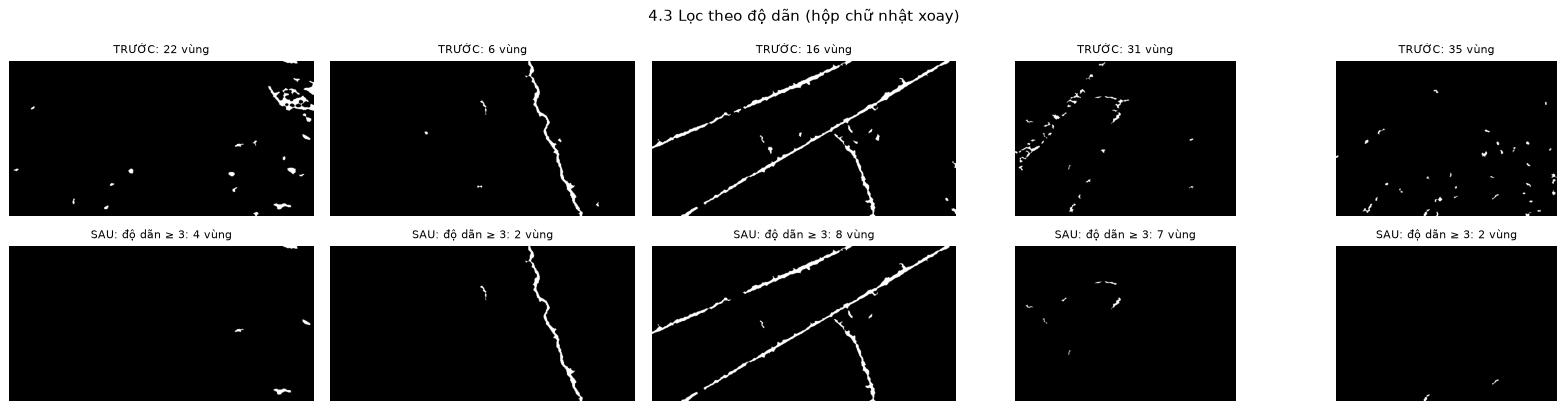

In [16]:
def elongation(comp, rect="rotated"):
    """Trục dài / trục ngắn của hộp chữ nhật bao vùng: xoay nhỏ nhất (minAreaRect) hoặc thẳng (boundingRect)."""
    pts = cv2.findNonZero(comp.astype(np.uint8))
    if rect == "axis":
        _, _, w, h = cv2.boundingRect(pts)
    else:
        (_, _), (w, h), _ = cv2.minAreaRect(pts)
    return max(w, h) / max(min(w, h), 1.0)

def elongation_filter(mask, e_min, rect="rotated"):
    n, lab, st, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    keep = np.zeros(n, bool)
    for i in range(1, n):
        x, y, w, h = st[i, :4]
        keep[i] = elongation(lab[y:y + h, x:x + w] == i, rect) >= e_min
    return keep[lab]

demo = []
for name, draw in [("đốm tròn r = 5", lambda m: cv2.circle(m, (30, 30), 5, 1, -1)),
                   ("đốm vuông 9×9", lambda m: cv2.rectangle(m, (26, 26), (34, 34), 1, -1)),
                   ("vết nứt ngang dày 2, dài 40", lambda m: cv2.line(m, (10, 30), (50, 30), 1, 2)),
                   ("vết nứt chéo 45° dày 2", lambda m: cv2.line(m, (10, 10), (50, 50), 1, 2)),
                   ("vết nứt cong (cung tròn)", lambda m: cv2.ellipse(m, (30, 45), (22, 22), 0, 200, 340, 1, 2))]:
    m = np.zeros((60, 60), np.uint8); draw(m)
    demo.append({"hình": name, "diện tích": int(m.sum()), "L/S hộp xoay": round(elongation(m > 0), 2),
                 "L/S hộp thẳng": round(elongation(m > 0, "axis"), 2), f"giữ (e_min = {P['e_min']})?": elongation(m > 0) >= P["e_min"]})
display(pd.DataFrame(demo))

S_F = [elongation_filter(m, P["e_min"]) for m in S_A]
show_before_after([u8(m) for m in S_A], [u8(m) for m in S_F],
                  [f"{ncc(m)} vùng" for m in S_A], [f"độ dãn ≥ {P['e_min']}: {ncc(m)} vùng" for m in S_F],
                  "4.3 Lọc theo độ dãn (hộp chữ nhật xoay)")

## 4.4 Quyết định mức ảnh: ảnh có vết nứt hay không (tổng diện tích < 0.3% ảnh thì mặt nạ rỗng)

| | |
|---|---|
| **Dùng gì** | Tính **tỉ lệ diện tích** của mặt nạ sau 4.3: s = (số pixel = 1) / (tổng số pixel) × 100%. Nếu **s < t_min** thì kết luận **ảnh không có vết nứt** và trả **mặt nạ rỗng**; ngược lại giữ nguyên |
| **Tại sao cần** | **19% ảnh không có vết nứt.** Mặt đường lành vẫn có khe nối, vết bẩn, mép vạch sơn tối và dài, nên sau 4.3 vẫn còn vài vùng. Các bước 4.2 và 4.3 xét **từng vùng riêng lẻ**, không biết cả ảnh có nứt hay không. Với ảnh lành, chỉ cần 1 pixel dự đoán là Dice = 0, trong khi mặt nạ rỗng được Dice = 1 |
| **Tại sao dùng tổng diện tích** | Đây là **đặc trưng vùng** đơn giản nhất của Ch7, áp dụng cho cả ảnh: ảnh có nứt thật cho mặt nạ lớn (GT trung bình khoảng 0.9% ảnh), ảnh lành chỉ còn mảnh vụn. Ngưỡng **tương đối (%)** không phụ thuộc kích thước ảnh |
| **Phương án khác** (bảng K10) | So sánh khả năng tách ảnh nứt / không nứt (AUC; 0.5 = đoán mò, 1 = hoàn hảo): **tổng diện tích 0.72** (tốt nhất), diện tích vùng lớn nhất 0.71, độ dài vùng dài nhất 0.67, số vùng 0.59, độ tương phản 0.46 (không tách được). **Không có 4.4**: Dice tune 0.250 so với **0.324**; chỉ 1/50 ảnh lành được trả rỗng |
| **Tham số chọn: t_min = 0.3%** (thử 0, 0.1, 0.2, 0.3, 0.4) | Cân bằng hai loại lỗi: tăng t_min thì đúng thêm ảnh lành nhưng xóa thêm ảnh có nứt nhỏ. Dice tune: 0 → 0.285, 0.1 → 0.300, 0.2 → 0.325, **0.3 → 0.328**, 0.4 → 0.328 |
| **Cái giá** | Ảnh có vết nứt **rất nhỏ** (dưới 0.3% ảnh) bị trả rỗng, mất toàn bộ vết nứt của ảnh đó |

```
s = diện tích sau 4.3 / diện tích ảnh      ảnh lành:     s = 0.05% < 0.3% → RỖNG    (Dice 0 → 1)
                                           ảnh có nứt:   s = 0.9%  ≥ 0.3% → giữ nguyên
                                           ảnh nứt nhỏ:  s = 0.2%  < 0.3% → RỖNG    (mất vết nứt: cái giá)
```

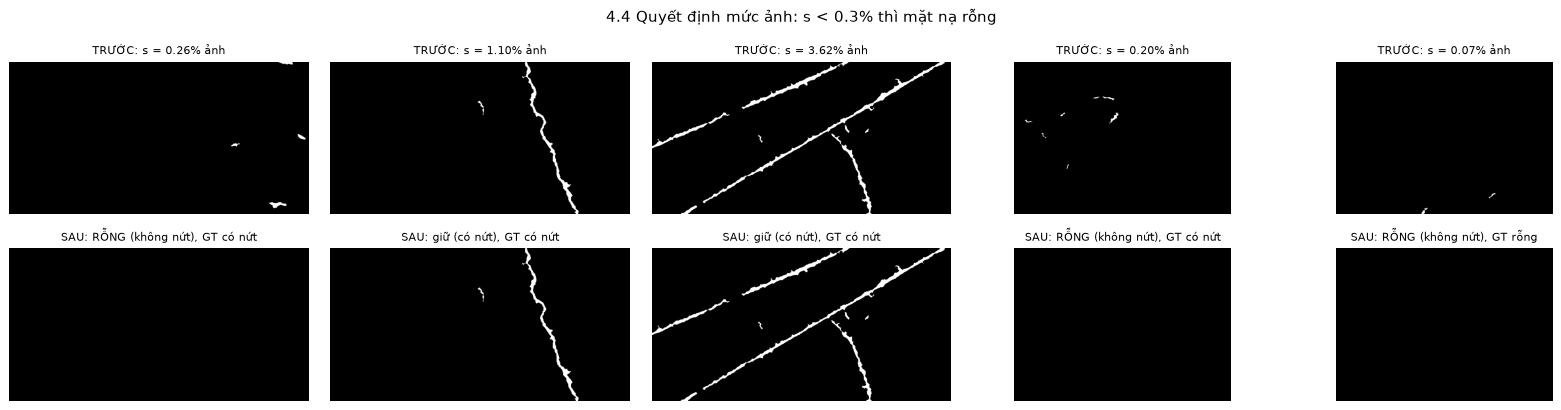

In [17]:
def image_decision(mask, tmin):
    s = mask.mean() * 100
    return (mask if s >= tmin else np.zeros_like(mask)), s

S_Z, S_S = zip(*[image_decision(m, P["tmin"]) for m in S_F])
show_before_after([u8(m) for m in S_F], [u8(m) for m in S_Z],
                  [f"s = {s:.2f}% ảnh" for s in S_S],
                  [("RỖNG (không nứt)" if not z.any() else "giữ (có nứt)") + f", GT {'rỗng' if not g.any() else 'có nứt'}" for z, g in zip(S_Z, S_GT)],
                  f"4.4 Quyết định mức ảnh: s < {P['tmin']}% thì mặt nạ rỗng")

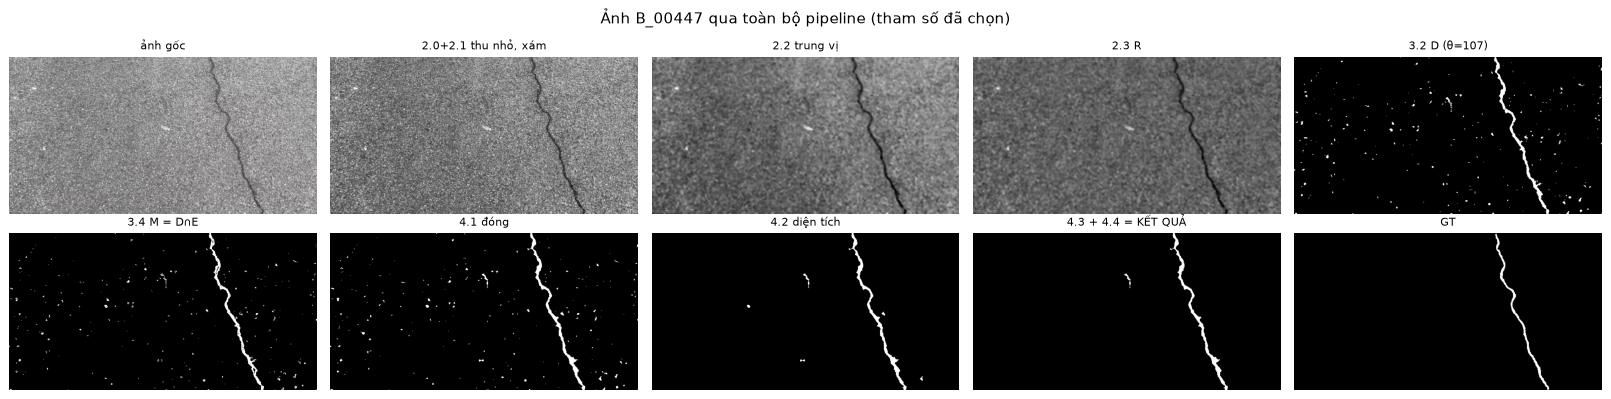

In [18]:
# ---- Toàn bộ pipeline. Các khóa tùy chọn (denoise, bg_mode, op, thresh, use_edge, morph, rect, post)
# ---- chỉ dùng cho các thí nghiệm kiểm chứng; mặc định là phương pháp đã chọn.
def raw_mask(img, p):
    """Bước 2 + 3: ảnh gốc -> mặt nạ thô M ở kích thước đã thu nhỏ (và các ảnh trung gian)."""
    small_ = resize_long(img, p["size"]) if p.get("size") else img
    gray = to_gray(small_)
    den = denoise(gray, p)
    ratio = (illumination_ratio(den, p["bg"], p.get("bg_mode", "median"), p.get("op", "div"))[0]
             if p.get("bg", 0) > 1 else den)
    if p.get("thresh", "triangle") == "otsu":
        theta, _ = cv2.threshold(ratio, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU); D = ratio < theta
    else:
        D, theta = dark_region(ratio, p["hist_w"])
    M = D & edge_region(ratio, p["dil"])[0] if p.get("use_edge", True) else D
    return M, dict(small=small_, gray=gray, den=den, ratio=ratio, D=D, theta=theta)

def post(M, p):
    """Bước 4: đóng -> lọc diện tích -> lọc độ dãn -> quyết định mức ảnh."""
    morph = p.get("morph", "close")
    C = closing(M, p["close"]) if morph == "close" else opening(M, p["close"]) if morph == "open" else M
    A = area_filter(C, p["a_min"])
    F = elongation_filter(A, p["e_min"], p.get("rect", "rotated"))
    Z, s = image_decision(F, p["tmin"])
    return Z, C, A, F

def pipeline(img, p, steps=False):
    """Ảnh gốc -> mặt nạ nhị phân ở KÍCH THƯỚC GỐC."""
    M, st = raw_mask(img, p)
    if steps:
        Z, C, A, F = post(M, p)
        return dict(st, M=M, C=C, A=A, F=F, Z=Z)
    Z = post(M, p)[0] if p.get("post", True) else M
    return to_orig(Z, img.shape[:2])

j = 1; st = pipeline(S_IMG[j], P, steps=True)
seq = [("ảnh gốc", rgb(small(S_IMG[j]))), ("2.0+2.1 thu nhỏ, xám", st["gray"]), ("2.2 trung vị", st["den"]), ("2.3 R", st["ratio"]),
       (f"3.2 D (θ={st['theta']})", st["D"]), ("3.4 M = D∩E", st["M"]), ("4.1 đóng", st["C"]), ("4.2 diện tích", st["A"]),
       ("4.3 + 4.4 = KẾT QUẢ", st["Z"]), ("GT", small(u8(S_GT[j]), nearest=True))]
fig, ax = plt.subplots(2, 5, figsize=(18, 4.6))
for a, (t, im) in zip(ax.ravel(), seq):
    a.imshow(im, cmap=None if im.ndim == 3 else "gray"); a.set_title(t); a.axis("off")
plt.suptitle(f"Ảnh {SAMPLE_IDS[j]} qua toàn bộ pipeline (tham số đã chọn)", fontsize=12); plt.tight_layout(); plt.show()

---
# Kiểm chứng lựa chọn phương pháp (trên tập tune, 300 ảnh train)

Mỗi bảng thay **đúng một** lựa chọn của pipeline bằng phương án khác, giữ nguyên mọi thứ còn lại (tham số P), rồi đo trên **tập tune** ở **kích thước gốc**. Tập test **không** được dùng ở đây.

| Bảng | Bước | So sánh |
|---|---|---|
| K1 | 2.0 | Kích thước 480 / **640** / 800 / gốc |
| K3 | 2.2 | **Trung vị 5×5** / trung vị 3×3 / Gauss 5×5 / không lọc |
| K4 | 2.3 | **Trung vị + phép chia** / trung vị + phép trừ / nền bằng phép đóng / không bù sáng |
| K5 | 3.1 | **W = 3** / W = 1 (không làm trơn) / W = 5 |
| K6 | 3.2 | **Tam giác** / Otsu |
| K7 | 3.3 | **D ∩ E** / chỉ D |
| K8 | 4.1 | **Phép đóng** / phép mở / không dùng |
| K9 | 4.2–4.3 | **Hộp xoay** / hộp thẳng / không lọc độ dãn / không lọc diện tích |
| K10 | 4.4 | Đặc trưng mức ảnh: **tổng diện tích** / diện tích vùng lớn nhất / độ dài / số vùng / độ tương phản; có / không có 4.4 |

In [19]:
COLS = ["Dice", "IoU", "Dice ảnh nứt", "Precision", "Recall", "ảnh rỗng đoán đúng", "ảnh nứt bị trả rỗng"]
VARIANTS = {}

def _cmp_worker(sid):
    img, gt = read_pair("train", sid)
    return [dict(id=sid, phương_án=name, **scores(pipeline(img, p), gt)) for name, p in VARIANTS.items()]

def compare(variants):
    global VARIANTS
    VARIANTS = variants
    df = pd.DataFrame(sum(pmap(_cmp_worker, TUNE_IDS), []))
    return summarize(df, "phương_án")[COLS]

CHOSEN = "★ đã chọn"
K = {}
K["K1"] = compare({"480 px": {**P, "size": 480}, f"{CHOSEN}: 640 px": P, "800 px": {**P, "size": 800}, "kích thước gốc": {**P, "size": None}})
K["K3"] = compare({f"{CHOSEN}: trung vị 5×5": P, "trung vị 3×3": {**P, "median": 3},
                   "Gauss 5×5": {**P, "denoise": "gauss"}, "không lọc": {**P, "median": 1}})
K["K4"] = compare({f"{CHOSEN}: nền trung vị, phép chia": P, "nền trung vị, phép trừ": {**P, "op": "sub"},
                   "nền = phép đóng 21×21": {**P, "bg_mode": "close", "bg": 21}, "không bù sáng": {**P, "bg": 0}})
K["K5"] = compare({f"{CHOSEN}: W = 3": P, "W = 1 (không làm trơn)": {**P, "hist_w": 1}, "W = 5": {**P, "hist_w": 5}})
K["K6"] = compare({f"{CHOSEN}: tam giác": P, "Otsu": {**P, "thresh": "otsu"}})
K["K7"] = compare({f"{CHOSEN}: M = D ∩ E": P, "M = D (bỏ biên)": {**P, "use_edge": False}})
K["K8"] = compare({f"{CHOSEN}: đóng 7×7": P, "mở 7×7": {**P, "morph": "open"}, "mở 3×3": {**P, "morph": "open", "close": 3},
                   "không dùng": {**P, "morph": "none"}})
K["K9"] = compare({f"{CHOSEN}: hộp xoay, e_min 3": P, "hộp thẳng, e_min 3": {**P, "rect": "axis"},
                   "không lọc độ dãn": {**P, "e_min": 0}, "không lọc diện tích": {**P, "a_min": 0}})
for k, v in K.items():
    print(k); display(v)

K1


,Dice,IoU,Dice ảnh nứt,Precision,Recall,ảnh rỗng đoán đúng,ảnh nứt bị trả rỗng
phương_án,,,,,,,
480 px,0.301,0.240,0.242,0.255,0.268,30/50,57
★ đã chọn: 640 px,0.324,0.258,0.273,0.315,0.279,29/50,55
800 px,0.305,0.238,0.274,0.344,0.257,23/50,55
kích thước gốc,0.225,0.177,0.162,0.249,0.139,27/50,101


K3


,Dice,IoU,Dice ảnh nứt,Precision,Recall,ảnh rỗng đoán đúng,ảnh nứt bị trả rỗng
phương_án,,,,,,,
★ đã chọn: trung vị 5×5,0.324,0.258,0.273,0.315,0.279,29/50,55
trung vị 3×3,0.291,0.228,0.253,0.324,0.244,24/50,61
Gauss 5×5,0.316,0.243,0.303,0.348,0.310,19/50,44
không lọc,0.224,0.167,0.217,0.272,0.224,13/50,57


K4


,Dice,IoU,Dice ảnh nứt,Precision,Recall,ảnh rỗng đoán đúng,ảnh nứt bị trả rỗng
phương_án,,,,,,,
"★ đã chọn: nền trung vị, phép chia",0.324,0.258,0.273,0.315,0.279,29/50,55
"nền trung vị, phép trừ",0.325,0.260,0.270,0.319,0.265,30/50,59
nền = phép đóng 21×21,0.286,0.229,0.231,0.308,0.209,28/50,85
không bù sáng,0.256,0.216,0.163,0.209,0.160,36/50,135


... (6 outputs left out)

K8


,Dice,IoU,Dice ảnh nứt,Precision,Recall,ảnh rỗng đoán đúng,ảnh nứt bị trả rỗng
phương_án,,,,,,,
★ đã chọn: đóng 7×7,0.324,0.258,0.273,0.315,0.279,29/50,55
mở 7×7,0.163,0.163,0.000,0.000,0.000,49/50,249
mở 3×3,0.247,0.214,0.137,0.189,0.120,40/50,139
không dùng,0.270,0.222,0.192,0.262,0.174,33/50,97


K9


,Dice,IoU,Dice ảnh nứt,Precision,Recall,ảnh rỗng đoán đúng,ảnh nứt bị trả rỗng
phương_án,,,,,,,
"★ đã chọn: hộp xoay, e_min 3",0.324,0.258,0.273,0.315,0.279,29/50,55
"hộp thẳng, e_min 3",0.208,0.190,0.074,0.091,0.074,44/50,180
không lọc độ dãn,0.267,0.190,0.293,0.276,0.382,7/50,6
không lọc diện tích,0.307,0.235,0.281,0.315,0.296,22/50,29


,"AUC (0.5 = đoán mò, 1 = tách hoàn hảo)",trung vị – ảnh có nứt,trung vị – ảnh không nứt
tổng_diện_tích,0.717,0.736,0.267
diện_tích_vùng_lớn_nhất,0.707,0.270,0.074
độ_dài_vùng_dài_nhất,0.673,0.166,0.082
số_vùng,0.594,7.000,5.000
độ_tương_phản,0.457,28.123,30.666


,Dice,IoU,Dice ảnh nứt,Precision,Recall,ảnh rỗng đoán đúng,ảnh nứt bị trả rỗng
phương_án,,,,,,,
★ đã chọn: có 4.4 (t_min 0.3%),0.324,0.258,0.273,0.315,0.279,29/50,55
không có 4.4,0.250,0.176,0.296,0.372,0.296,1/50,3


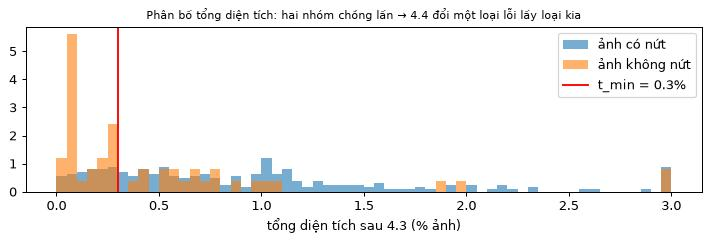

In [20]:
# K10 – Đặc trưng mức ảnh cho bước 4.4: tách ảnh có nứt / không nứt tốt đến đâu?
def feat_worker(sid):
    img, gt = read_pair("train", sid)
    M, st = raw_mask(img, P)
    F = post(M, {**P, "tmin": 0})[3]
    n, lab, stt, _ = cv2.connectedComponentsWithStats(F.astype(np.uint8), connectivity=8)
    L = max([max(cv2.minAreaRect(cv2.findNonZero((lab == i).astype(np.uint8)))[1]) for i in range(1, n)], default=0)
    return dict(id=sid, có_nứt=gt.any(),
                tổng_diện_tích=F.mean() * 100,
                diện_tích_vùng_lớn_nhất=(stt[1:, 4].max() if n > 1 else 0) / F.size * 100,
                độ_dài_vùng_dài_nhất=L / max(F.shape),
                số_vùng=n - 1,
                độ_tương_phản=(128 - st["ratio"][F].mean()) if F.any() else 0)

def auc(pos, neg):
    """AUC = xác suất một ảnh có nứt có đặc trưng lớn hơn một ảnh không nứt (Mann–Whitney)."""
    pos, neg = np.asarray(pos)[:, None], np.asarray(neg)[None, :]
    return float((pos > neg).mean() + 0.5 * (pos == neg).mean())

FEAT = pd.DataFrame(pmap(feat_worker, TUNE_IDS))
fk = [c for c in FEAT if c not in ("id", "có_nứt")]
K["K10"] = pd.DataFrame({"AUC (0.5 = đoán mò, 1 = tách hoàn hảo)": [auc(FEAT[FEAT.có_nứt][c], FEAT[~FEAT.có_nứt][c]) for c in fk],
                         "trung vị – ảnh có nứt": [FEAT[FEAT.có_nứt][c].median() for c in fk],
                         "trung vị – ảnh không nứt": [FEAT[~FEAT.có_nứt][c].median() for c in fk]}, index=fk)
display(K["K10"])
display(compare({f"{CHOSEN}: có 4.4 (t_min 0.3%)": P, "không có 4.4": {**P, "tmin": 0.0}}))
fig, ax = plt.subplots(figsize=(8, 2.8))
bins = np.linspace(0, 3, 61)
ax.hist(FEAT[FEAT.có_nứt].tổng_diện_tích.clip(0, 3), bins, alpha=.6, label="ảnh có nứt", density=True)
ax.hist(FEAT[~FEAT.có_nứt].tổng_diện_tích.clip(0, 3), bins, alpha=.6, label="ảnh không nứt", density=True)
ax.axvline(P["tmin"], color="red", label=f"t_min = {P['tmin']}%"); ax.set_xlabel("tổng diện tích sau 4.3 (% ảnh)"); ax.legend()
ax.set_title("Phân bố tổng diện tích: hai nhóm chồng lấn → 4.4 đổi một loại lỗi lấy loại kia"); plt.tight_layout(); plt.show()

### Tóm tắt kiểm chứng (Dice tune của phương pháp đã chọn = **0.324**)

| Bảng | Lựa chọn | Phương án khác → Dice tune | Kết luận |
|---|---|---|---|
| K1 | Thu nhỏ 640 px | gốc 0.225 · 480 px 0.301 · 800 px 0.305 | Thu nhỏ là **bắt buộc**; 640 tốt nhất |
| K3 | Trung vị 5×5 | không lọc 0.224 · trung vị 3×3 0.291 · Gauss 5×5 0.316 | Trung vị tốt nhất. Gauss sát nút nhưng báo nhầm nhiều hơn trên ảnh lành (19/50 so với 29/50 ảnh trả rỗng đúng) |
| K4 | Nền trung vị + phép chia | không bù sáng 0.256 · nền = phép đóng 0.286 · phép trừ 0.325 | Bù sáng là **bắt buộc**; nền phải dùng trung vị. Chia và trừ tương đương |
| K5 | Làm trơn W = 3 | W = 1: 0.303 · W = 5: 0.319 | Làm trơn có ích (+0.021) |
| K6 | Ngưỡng tam giác | Otsu: **0.082** | Lựa chọn **quan trọng nhất**: Otsu thất bại với lược đồ lệch lớp |
| K7 | D ∩ E | chỉ D: 0.296 | Điều kiện biên giúp nhận ra ảnh lành |
| K8 | Phép đóng 7×7 | mở 7×7: 0.163 (xóa sạch vết nứt) · mở 3×3: 0.247 · không dùng: 0.270 | Phải dùng **đóng**, không dùng **mở** |
| K9 | Hộp xoay, lọc diện tích | hộp thẳng 0.208 · không lọc độ dãn 0.267 · không lọc diện tích 0.307 | Hộp **xoay** là bắt buộc (vết nứt chéo) |
| K10 | Có 4.4 (tổng diện tích) | không có 4.4: 0.250; AUC: tổng diện tích 0.72 > vùng lớn nhất 0.71 > độ dài 0.67 > số vùng 0.59 > tương phản 0.46 | 4.4 cần thiết; tổng diện tích là đặc trưng tốt nhất. AUC 0.72 cho thấy ảnh lành và ảnh nứt vẫn chồng lấn |

**Những điểm cần nói thật trên slide:**
* Phép chia và phép trừ cho kết quả **như nhau** trên bộ này (K4). Chọn phép chia dựa trên lý thuyết (ánh sáng tác động kiểu nhân), không phải vì số liệu.
* Trung vị thắng Gauss chủ yếu nhờ **ít báo nhầm trên ảnh lành**; trên ảnh có nứt, Gauss nhỉnh hơn một chút (K3).
* Điều kiện biên (K7) và bước 4.4 (K10) giúp nhiều trên **ảnh lành**, nhưng làm giảm nhẹ Dice trên **ảnh có nứt**: đây là đánh đổi có chủ đích, vì 19% ảnh không có nứt.

---
# Chọn tham số: thử toàn bộ lưới trên tune (300 ảnh train), xác nhận trên val (498 ảnh)

| Tham số | Bước | Dãy thử | Lý do của dãy thử |
|---|---|---|---|
| `size` | 2.0 | 480, 640 | 800 và kích thước gốc đã kém rõ ở K1 |
| `median` | 2.2 | 3, 5 | ≥ 7 xóa vết nứt rộng ≤ 3 px |
| `bg` | 2.3 | 31, 51, 71 | Lớn hơn nhiều lần bề rộng vết nứt, nhỏ hơn vệt bóng |
| `hist_w` | 3.1 | 3, 5 | Giá trị W thường dùng trong giáo trình |
| `dil` | 3.3 | 3, 5, 7 | Từ vừa phủ thân vết nứt tới phủ gần hết ảnh |
| `close` | 4.1 | 5, 7 | Nối khe đứt 4–6 px |
| `a_min` | 4.2 | 30, 60, 120 | Đoạn nứt dài khoảng 10, 20, 40 px |
| `e_min` | 4.3 | 2, 3 | Vùng dài gấp 2 hoặc 3 lần bề rộng |
| `tmin` (%) | 4.4 | 0, 0.1, 0.2, 0.3, 0.4 | Từ không dùng tới gần một nửa diện tích nứt trung bình (0.9%) |

* Tổng cộng 2 × 2 × 3 × 2 × 3 × 2 × 3 × 2 × 5 = **4320 cấu hình**, thử **toàn bộ**.
* **Tiêu chí:** Dice trung bình theo ảnh (gồm cả ảnh không nứt) – đúng với độ đo báo cáo.
* **Tăng tốc:** mặt nạ thô M chỉ phụ thuộc 5 tham số của bước 2–3 (72 tổ hợp), được tính một lần rồi dùng lại cho 12 tổ hợp 4.1–4.3; 5 giá trị t_min dùng chung một mặt nạ. Khi tune, Dice tính ở **ảnh đã thu nhỏ** (nhanh hơn khoảng 5 lần); ở val và test luôn tính ở **kích thước gốc**.
* **Xác nhận trên val:** 10 cấu hình tốt nhất trên tune chạy trên **toàn bộ 498 ảnh val**; chọn cấu hình có **Dice val cao nhất**. Ô cuối kiểm tra cấu hình này trùng với P dùng ở các phần trên.

In [21]:
PRE_KEYS, POST_KEYS = ["size", "median", "bg", "hist_w", "dil"], ["close", "a_min", "e_min"]
PRE_GRID = [dict(zip(PRE_KEYS, v)) for v in itertools.product(*(TUNE_SPACE[k] for k in PRE_KEYS))]
POST_GRID = [dict(zip(POST_KEYS, v)) for v in itertools.product(*(TUNE_SPACE[k] for k in POST_KEYS))]

def tune_worker(sid):
    img, gt = read_pair("train", sid)
    out = []
    for i, pp in enumerate(PRE_GRID):
        M = raw_mask(img, {**P0, **pp})[0]
        gts = cv2.resize(u8(gt), (M.shape[1], M.shape[0]), interpolation=cv2.INTER_NEAREST) > 0   # GT ở cùng kích thước
        for j, qp in enumerate(POST_GRID):
            F = post(M, {**P0, **qp, "tmin": 0})[3]
            s_ = F.mean() * 100
            for t in TUNE_SPACE["tmin"]:
                sc = scores(F if s_ >= t else np.zeros_like(F), gts)
                out.append((sid, i, j, t, sc["dice"], sc["iou"], sc["gt_pos"], sc["pred_pos"]))
    return out

t0 = time.time()
R = pd.DataFrame(sum(pmap(tune_worker, TUNE_IDS), []), columns=["id", "i", "j", "tmin", "dice", "iou", "gt_pos", "pred_pos"])
agg = R.groupby(["i", "j", "tmin"]).agg(dice=("dice", "mean"), iou=("iou", "mean")).reset_index()
agg["dice ảnh nứt"] = R[R.gt_pos].groupby(["i", "j", "tmin"]).dice.mean().values
agg["ảnh rỗng đúng"] = R[~R.gt_pos].groupby(["i", "j", "tmin"]).pred_pos.apply(lambda x: (~x).sum()).values
TUNE_LOG = pd.concat([pd.DataFrame([PRE_GRID[i] for i in agg.i]), pd.DataFrame([POST_GRID[j] for j in agg.j]),
                      agg.drop(columns=["i", "j"])], axis=1)
keys = PRE_KEYS + POST_KEYS + ["tmin"]
TUNE_LOG["khởi đầu"] = np.all([TUNE_LOG[k] == P0[k] for k in keys], axis=0)
TUNE_LOG = TUNE_LOG.sort_values("dice", ascending=False).reset_index(drop=True)
TUNE_LOG.to_csv(os.path.join(RES, "tune_log.csv"), index=False)
r0 = TUNE_LOG[TUNE_LOG["khởi đầu"]].iloc[0]
print(f"{len(TUNE_LOG)} cấu hình × {len(TUNE_IDS)} ảnh, {time.time()-t0:.0f}s")
print(f"Tham số khởi đầu P0: Dice tune {r0.dice:.3f}, hạng {TUNE_LOG.index[TUNE_LOG['khởi đầu']][0] + 1}/{len(TUNE_LOG)}")
TUNE_LOG.head(10)

4320 cấu hình × 300 ảnh, 127s
Tham số khởi đầu P0: Dice tune 0.262, hạng 2287/4320


,size,median,bg,hist_w,dil,close,a_min,e_min,tmin,dice,iou,dice ảnh nứt,ảnh rỗng đúng,khởi đầu
0,480,5,31,3,3,7,60,2,0.4,0.328,0.264,0.251,36,False
1,480,5,31,3,3,7,30,3,0.3,0.328,0.265,0.247,37,False
2,480,5,31,3,3,7,30,3,0.4,0.327,0.270,0.230,41,False
3,480,5,31,3,3,7,60,3,0.3,0.327,0.268,0.234,40,False
4,640,5,51,3,3,7,60,3,0.3,0.326,0.261,0.260,33,False
5,480,5,31,3,3,7,60,3,0.2,0.325,0.262,0.247,36,False
6,480,5,31,3,3,7,60,2,0.3,0.322,0.255,0.259,32,False
7,480,5,31,3,5,7,30,3,0.4,0.320,0.260,0.236,37,False
8,640,5,71,3,3,7,60,3,0.4,0.319,0.259,0.244,35,False
9,640,5,71,3,3,7,30,3,0.3,0.319,0.252,0.263,30,False


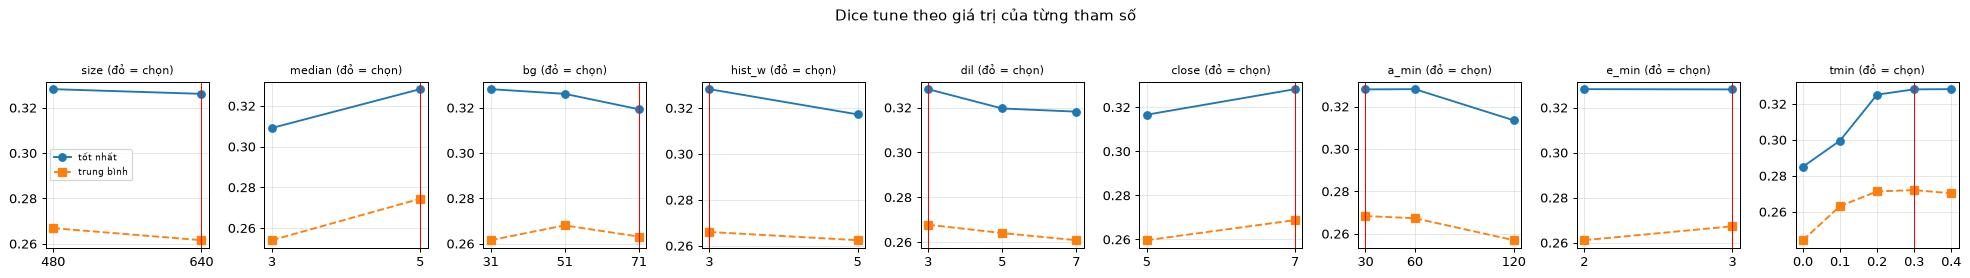

,0.0,0.1,0.2,0.3,0.4,2.0,3.0,5.0,7.0,30.0,31.0,51.0,60.0,71.0,120.0,480.0,640.0
tham số,,,,,,,,,,,,,,,,,
size,,,,,,,,,,,,,,,,0.328,0.326
median,,,,,,,0.309,0.328,,,,,,,,,
bg,,,,,,,,,,,0.328,0.326,,0.319,,,
hist_w,,,,,,,0.328,0.317,,,,,,,,,
dil,,,,,,,0.328,0.32,0.318,,,,,,,,
close,,,,,,,,0.317,0.328,,,,,,,,
a_min,,,,,,,,,,0.328,,,0.328,,0.314,,
e_min,,,,,,0.328,0.328,,,,,,,,,,
tmin,0.285,0.3,0.325,0.328,0.328,,,,,,,,,,,,


In [22]:
# Ảnh hưởng của từng tham số: Dice tune TỐT NHẤT (các tham số khác tối ưu) và TRUNG BÌNH theo từng giá trị
fig, ax = plt.subplots(1, len(keys), figsize=(22, 2.9))
eff = {}
for a, k in zip(ax, keys):
    g = TUNE_LOG.groupby(k).dice
    a.plot(g.max().index, g.max().values, "o-", label="tốt nhất"); a.plot(g.mean().index, g.mean().values, "s--", label="trung bình")
    a.axvline(P[k], color="red", lw=0.8); a.set_title(f"{k} (đỏ = chọn)"); a.set_xticks(list(g.max().index)); a.grid(alpha=.3)
    eff[k] = g.max().round(3).to_dict()
ax[0].legend(fontsize=7); plt.suptitle("Dice tune theo giá trị của từng tham số", y=1.05); plt.tight_layout(); plt.show()
pd.DataFrame({k: pd.Series(v) for k, v in eff.items()}).T.rename_axis("tham số").fillna("")

In [23]:
# Xác nhận 10 cấu hình tốt nhất trên toàn bộ val (kích thước gốc)
TOP = [{k: (float(r[k]) if k == "tmin" else int(r[k])) for k in keys} for _, r in TUNE_LOG.head(10).iterrows()]
CANDS = TOP + [P0]

def val_worker(sid):
    img, gt = read_pair("val", sid)
    out, cache = [], {}
    for c, p in enumerate(CANDS):
        kpre = tuple(p[k] for k in PRE_KEYS)
        if kpre not in cache:
            cache[kpre] = raw_mask(img, p)[0]
        out.append(dict(id=sid, cấu_hình=c, **scores(to_orig(post(cache[kpre], p)[0], gt.shape), gt)))
    return out

t0 = time.time()
V = pd.DataFrame(sum(pmap(val_worker, VAL_IDS), []))
VAL_LOG = summarize(V, "cấu_hình")[COLS]
VAL_LOG.insert(0, "Dice tune", list(TUNE_LOG.head(10).dice) + [r0.dice])
VAL_LOG.insert(0, "tham số", [" ".join(f"{k}={p[k]}" for k in keys) for p in CANDS])
VAL_LOG.index = [f"top{c+1}" for c in range(10)] + ["khởi đầu P0"]
VAL_LOG.to_csv(os.path.join(RES, "val_log.csv"))
best = int(np.argmax(VAL_LOG["Dice"].values[:10]))
assert TOP[best] == {k: P[k] for k in keys}, f"Cấu hình chọn trên val {TOP[best]} khác P"
json.dump(P, open(os.path.join(RES, "best_params.json"), "w"), indent=1)
print(f"{time.time()-t0:.0f}s | chọn top{best+1} = P: {P}")
VAL_LOG

8s | chọn top10 = P: {'size': 640, 'median': 5, 'bg': 71, 'hist_w': 3, 'dil': 3, 'close': 7, 'a_min': 30, 'e_min': 3, 'tmin': 0.3}


,tham số,Dice tune,Dice,IoU,Dice ảnh nứt,Precision,Recall,ảnh rỗng đoán đúng,ảnh nứt bị trả rỗng
top1,size=480 median=5 bg=31 hist_w=3 dil=3 close=7...,0.328,0.348,0.285,0.288,0.304,0.312,63/115,76
top2,size=480 median=5 bg=31 hist_w=3 dil=3 close=7...,0.328,0.354,0.291,0.285,0.319,0.292,67/115,90
top3,size=480 median=5 bg=31 hist_w=3 dil=3 close=7...,0.327,0.351,0.293,0.269,0.291,0.280,72/115,122
top4,size=480 median=5 bg=31 hist_w=3 dil=3 close=7...,0.327,0.349,0.289,0.273,0.309,0.277,69/115,109
top5,size=640 median=5 bg=51 hist_w=3 dil=3 close=7...,0.326,0.362,0.300,0.288,0.342,0.279,70/115,92
top6,size=480 median=5 bg=31 hist_w=3 dil=3 close=7...,0.325,0.340,0.278,0.282,0.331,0.283,61/115,79
top7,size=480 median=5 bg=31 hist_w=3 dil=3 close=7...,0.322,0.348,0.282,0.298,0.321,0.319,59/115,52
top8,size=480 median=5 bg=31 hist_w=3 dil=5 close=7...,0.320,0.354,0.293,0.277,0.295,0.293,70/115,105
top9,size=640 median=5 bg=71 hist_w=3 dil=3 close=7...,0.319,0.356,0.300,0.267,0.295,0.270,75/115,125
top10,size=640 median=5 bg=71 hist_w=3 dil=3 close=7...,0.319,0.364,0.300,0.296,0.334,0.297,68/115,85


### Phân tích kết quả chọn tham số

**Cấu hình chọn (Dice val cao nhất):** size **640**, trung vị **5×5**, nền **71×71**, W = **3**, giãn biên **3×3**, đóng **7×7**, a_min = **30**, e_min = **3**, t_min = **0.3%**. Cấu hình này xếp hạng 10 trên tune (0.319) nhưng có **Dice val cao nhất: 0.364**. Mười cấu hình đầu bảng tune chỉ chênh nhau 0.009, nên chọn trên val (498 ảnh) đáng tin hơn chọn trên tune (300 ảnh).

| Bước | Tham số | Khởi đầu P0 | **Chọn** | Dice tune tốt nhất theo từng giá trị | Lý do |
|---|---|---|---|---|---|
| 2.0 | size | 640 | **640** | 480: 0.328 · 640: 0.326 | Gần như bằng nhau trên tune; 640 tốt hơn trên val và ở K1 |
| 2.2 | trung vị | 3×3 | **5×5** | 3: 0.309 · 5: **0.328** | Vết nứt rộng 3–5 px chịu được 5×5; nền sỏi thô cần khử mạnh hơn |
| 2.3 | cửa sổ nền | 31 | **71** | 31: **0.328** · 51: 0.326 · 71: 0.319 | Ít nhạy (chênh ≤ 0.009) |
| 3.1 | W | 3 | **3** | 3: **0.328** · 5: 0.317 | W = 5 làm tù đuôi tối |
| 3.3 | giãn biên | 7×7 | **3×3** | 3: **0.328** · 5: 0.320 · 7: 0.318 | Giãn ít thì E chặt, loại được vệt tối không có biên |
| 4.1 | phép đóng | 7×7 | **7×7** | 5: 0.317 · 7: **0.328** | Nối được khe đứt dài hơn |
| 4.2 | a_min | 60 | **30** | 30: **0.328** · 60: **0.328** · 120: 0.314 | Giữ mảnh nứt ngắn; quyết định "có nứt" để cho 4.4 |
| 4.3 | e_min | 2 | **3** | 2: **0.328** · 3: **0.328** | Vết nứt chủ yếu thẳng; loại thêm vệt tối gần tròn |
| 4.4 | t_min | 0.2% | **0.3%** | 0: 0.285 · 0.1: 0.300 · 0.2: 0.325 · 0.3: **0.328** · 0.4: **0.328** | Tham số ảnh hưởng mạnh nhất (+0.043 so với không dùng) |

* Tham số khởi đầu P0 xếp hạng **2287/4320** (Dice tune 0.262). Chọn tham số đưa Dice val từ **0.308 lên 0.364**.
* **Đánh đổi:** trên val, P trả rỗng đúng **68/115** ảnh lành (P0: 37/115), nhưng làm mất **85/383** ảnh có nứt nhỏ (P0: 39).

---
# Bước 5 – Đánh giá trên tập test (231 ảnh)

Độ đo: xem mục *Độ đo*. Mọi độ đo tính ở **kích thước gốc**. Tập test chỉ được dùng **một lần**, ở đây.

### Đối chứng (Chương 5)
| Đối chứng | Cách làm | Tại sao chọn làm đối chứng |
|---|---|---|
| **Otsu** | Ảnh xám gốc, ngưỡng Otsu toàn cục, pixel tối hơn ngưỡng là vết nứt | Cách tách ngưỡng tự động cơ bản nhất: cho thấy cần bù sáng và cần ngưỡng hợp với lược đồ lệch lớp |
| **Canny** | Ảnh xám gốc, `cv2.Canny(50, 150)`, pixel biên là vết nứt | Bộ dò biên chuẩn. Ngưỡng thấp : cao = 1 : 3 theo khuyến nghị của Canny; 50/150 là cặp giá trị thông dụng cho ảnh 8 bit. Cho thấy chỉ dò biên là chưa đủ |

### Các phiên bản pipeline
* **Pipeline – tham số khởi đầu P0** và **Pipeline – tham số đã chọn P**: thấy lợi ích của việc chọn tham số.
* **Bỏ từng bước** (dùng P, mỗi lần bỏ một bước): bỏ 2.0 (kích thước gốc) · bỏ 2.3 · bỏ 3.1 (W = 1) · bỏ 3.3 (M = D) · bỏ 4.4 · bỏ cả bước 4.

In [24]:
def baseline_otsu(img):
    _, m = cv2.threshold(to_gray(img), 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    return m > 0

def baseline_canny(img):
    return cv2.Canny(to_gray(img), 50, 150) > 0

MAIN, START = "Pipeline – tham số đã chọn P", "Pipeline – tham số khởi đầu P0"
METHODS = {
    "Đối chứng: Otsu": baseline_otsu,
    "Đối chứng: Canny": baseline_canny,
    START: lambda im: pipeline(im, P0),
    MAIN: lambda im: pipeline(im, P),
    "Bỏ 2.0 (kích thước gốc)": lambda im: pipeline(im, {**P, "size": None}),
    "Bỏ 2.3 (không bù sáng)": lambda im: pipeline(im, {**P, "bg": 0}),
    "Bỏ 3.1 (W = 1)": lambda im: pipeline(im, {**P, "hist_w": 1}),
    "Bỏ 3.3 (M = D)": lambda im: pipeline(im, {**P, "use_edge": False}),
    "Bỏ 4.4 (t_min = 0)": lambda im: pipeline(im, {**P, "tmin": 0.0}),
    "Bỏ bước 4 (không hậu xử lý)": lambda im: pipeline(im, {**P, "post": False}),
}

def test_worker(sid):
    img, gt = read_pair("test", sid)
    return [dict(id=sid, nhóm=sid[0], phương_pháp=name, **scores(f(img), gt)) for name, f in METHODS.items()]

t0 = time.time()
PER_IMAGE = pd.DataFrame(sum(pmap(test_worker, TEST_IDS), []))
PER_IMAGE.to_csv(os.path.join(RES, "test_per_image.csv"), index=False)
SUMMARY = summarize(PER_IMAGE, "phương_pháp")
SUMMARY.to_csv(os.path.join(RES, "test_summary.csv"))
print(f"{time.time()-t0:.0f}s")
SUMMARY

7s


,số ảnh,Dice,IoU,Dice ảnh nứt,IoU ảnh nứt,Precision,Recall,Dice gộp,IoU gộp,ảnh rỗng đoán đúng,ảnh nứt bị trả rỗng
phương_pháp,,,,,,,,,,,
Đối chứng: Otsu,231,0.024,0.012,0.030,0.015,0.015,0.723,0.027,0.014,0/45,0
Đối chứng: Canny,231,0.018,0.009,0.022,0.011,0.012,0.352,0.019,0.010,0/45,0
Pipeline – tham số khởi đầu P0,231,0.296,0.227,0.319,0.233,0.399,0.314,0.345,0.209,9/45,32
Pipeline – tham số đã chọn P,231,0.339,0.274,0.303,0.222,0.328,0.312,0.426,0.271,22/45,45
Bỏ 2.0 (kích thước gốc),231,0.267,0.214,0.197,0.132,0.311,0.168,0.255,0.146,25/45,71
Bỏ 2.3 (không bù sáng),231,0.283,0.239,0.206,0.151,0.257,0.200,0.316,0.187,27/45,97
Bỏ 3.1 (W = 1),231,0.340,0.272,0.304,0.220,0.307,0.341,0.406,0.255,22/45,41
Bỏ 3.3 (M = D),231,0.329,0.259,0.323,0.235,0.347,0.345,0.392,0.244,16/45,36
Bỏ 4.4 (t_min = 0),231,0.274,0.200,0.329,0.238,0.406,0.329,0.431,0.275,2/45,3


In [25]:
# Kết quả theo nhóm ảnh A / B / C (Dice trung bình theo ảnh; trong ngoặc: Dice trên ảnh có nứt)
sel = ["Đối chứng: Otsu", "Đối chứng: Canny", START, MAIN]
d = PER_IMAGE[PER_IMAGE.phương_pháp.isin(sel)]
tab = (d.groupby(["phương_pháp", "nhóm"], sort=False).dice.mean().round(3).astype(str) + " (" +
       d[d.gt_pos].groupby(["phương_pháp", "nhóm"], sort=False).dice.mean().round(3).astype(str) + ")")
BY_GROUP = tab.unstack("nhóm")[["A", "B", "C"]].loc[sel]
BY_GROUP.columns = [f"{g} ({(PER_IMAGE[(PER_IMAGE.phương_pháp == MAIN) & (PER_IMAGE.nhóm == g)]).shape[0]} ảnh)" for g in "ABC"]
BY_GROUP.to_csv(os.path.join(RES, "test_by_group.csv"))
BY_GROUP

,A (13 ảnh),B (82 ảnh),C (136 ảnh)
phương_pháp,,,
Đối chứng: Otsu,0.034 (0.034),0.032 (0.033),0.018 (0.026)
Đối chứng: Canny,0.024 (0.024),0.02 (0.02),0.016 (0.023)
Pipeline – tham số khởi đầu P0,0.183 (0.183),0.565 (0.56),0.144 (0.126)
Pipeline – tham số đã chọn P,0.126 (0.126),0.554 (0.548),0.231 (0.113)


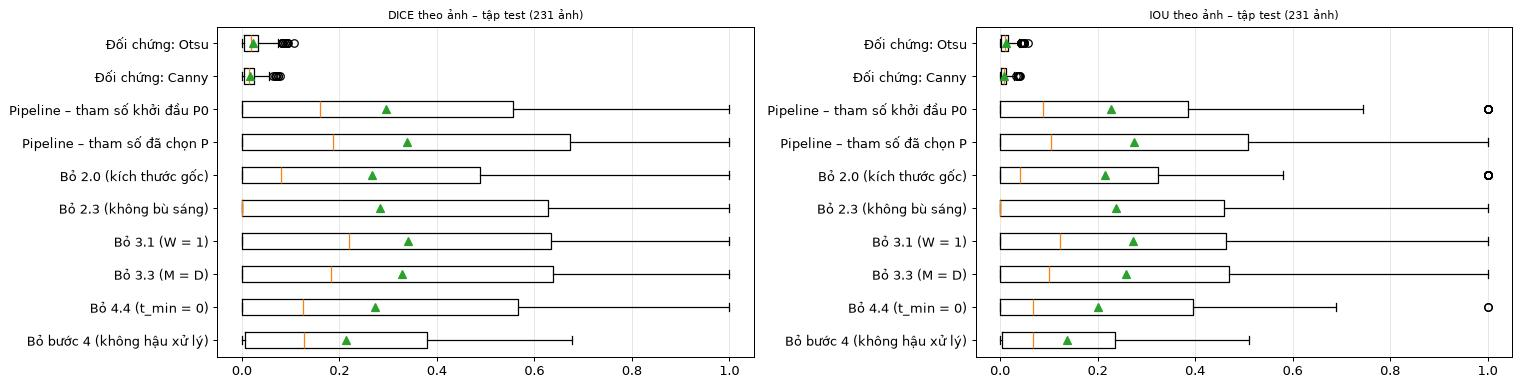

Tỉ lệ ảnh test mà pipeline (P) có Dice CAO HƠN / BẰNG:


,cao hơn,bằng
phương_pháp,,
Bỏ 2.0 (kích thước gốc),39%,31%
Bỏ 2.3 (không bù sáng),47%,38%
Bỏ 3.1 (W = 1),31%,40%
Bỏ 3.3 (M = D),29%,36%
Bỏ 4.4 (t_min = 0),9%,77%
Bỏ bước 4 (không hậu xử lý),52%,11%
Pipeline – tham số khởi đầu P0,34%,30%
Đối chứng: Canny,62%,10%
Đối chứng: Otsu,62%,10%


In [26]:
fig, ax = plt.subplots(1, 2, figsize=(17, 4.4))
names = list(METHODS)
for a, k in zip(ax, ["dice", "iou"]):
    a.boxplot([PER_IMAGE[PER_IMAGE.phương_pháp == n][k] for n in names], orientation="horizontal", tick_labels=names, showmeans=True)
    a.set_title(f"{k.upper()} theo ảnh – tập test (231 ảnh)"); a.invert_yaxis(); a.grid(alpha=.3, axis="x")
plt.tight_layout(); plt.show()
pv = PER_IMAGE.pivot(index="id", columns="phương_pháp", values="dice")
print("Tỉ lệ ảnh test mà pipeline (P) có Dice CAO HƠN / BẰNG:")
display(pd.DataFrame({"cao hơn": (pv[MAIN].values[:, None] > pv.drop(columns=MAIN).values).mean(0),
                      "bằng": (pv[MAIN].values[:, None] == pv.drop(columns=MAIN).values).mean(0)},
                     index=pv.drop(columns=MAIN).columns).map(lambda v: f"{v*100:.0f}%"))

### Trực quan hóa: phủ mặt nạ đỏ lên ảnh gốc (tập test)
Các hàng: ảnh gốc, GT, Otsu, Canny, pipeline, và **bản đồ lỗi** của pipeline (**xanh lá** = TP, **đỏ** = FP báo nhầm, **xanh dương** = FN bỏ sót). Ảnh được thu nhỏ **chỉ để hiển thị**.

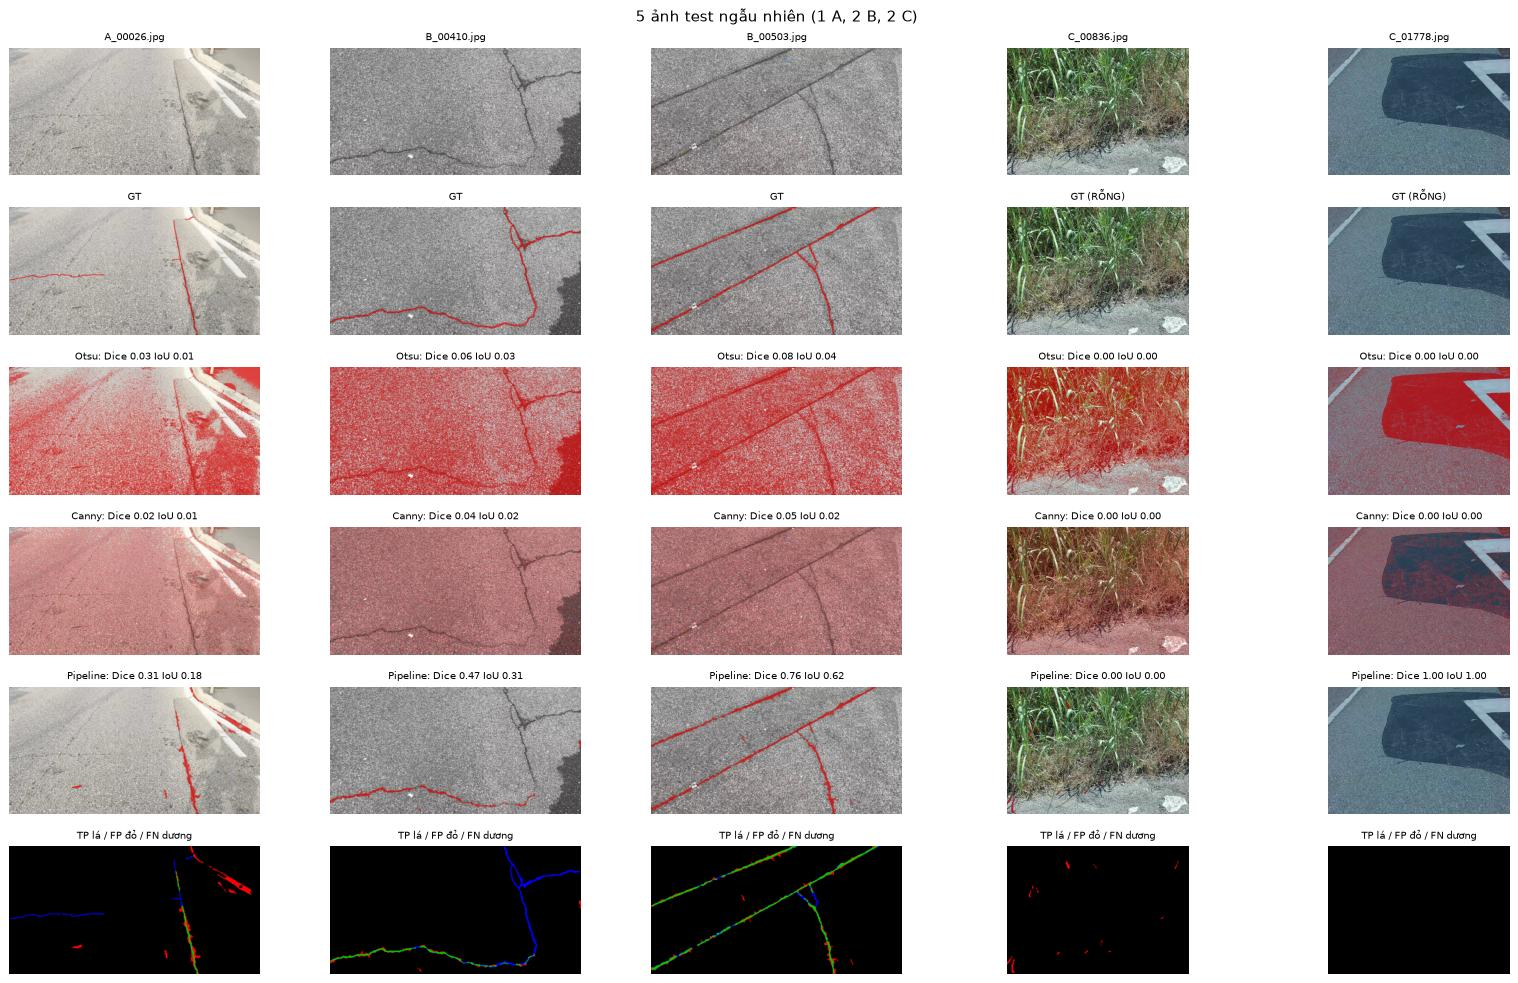

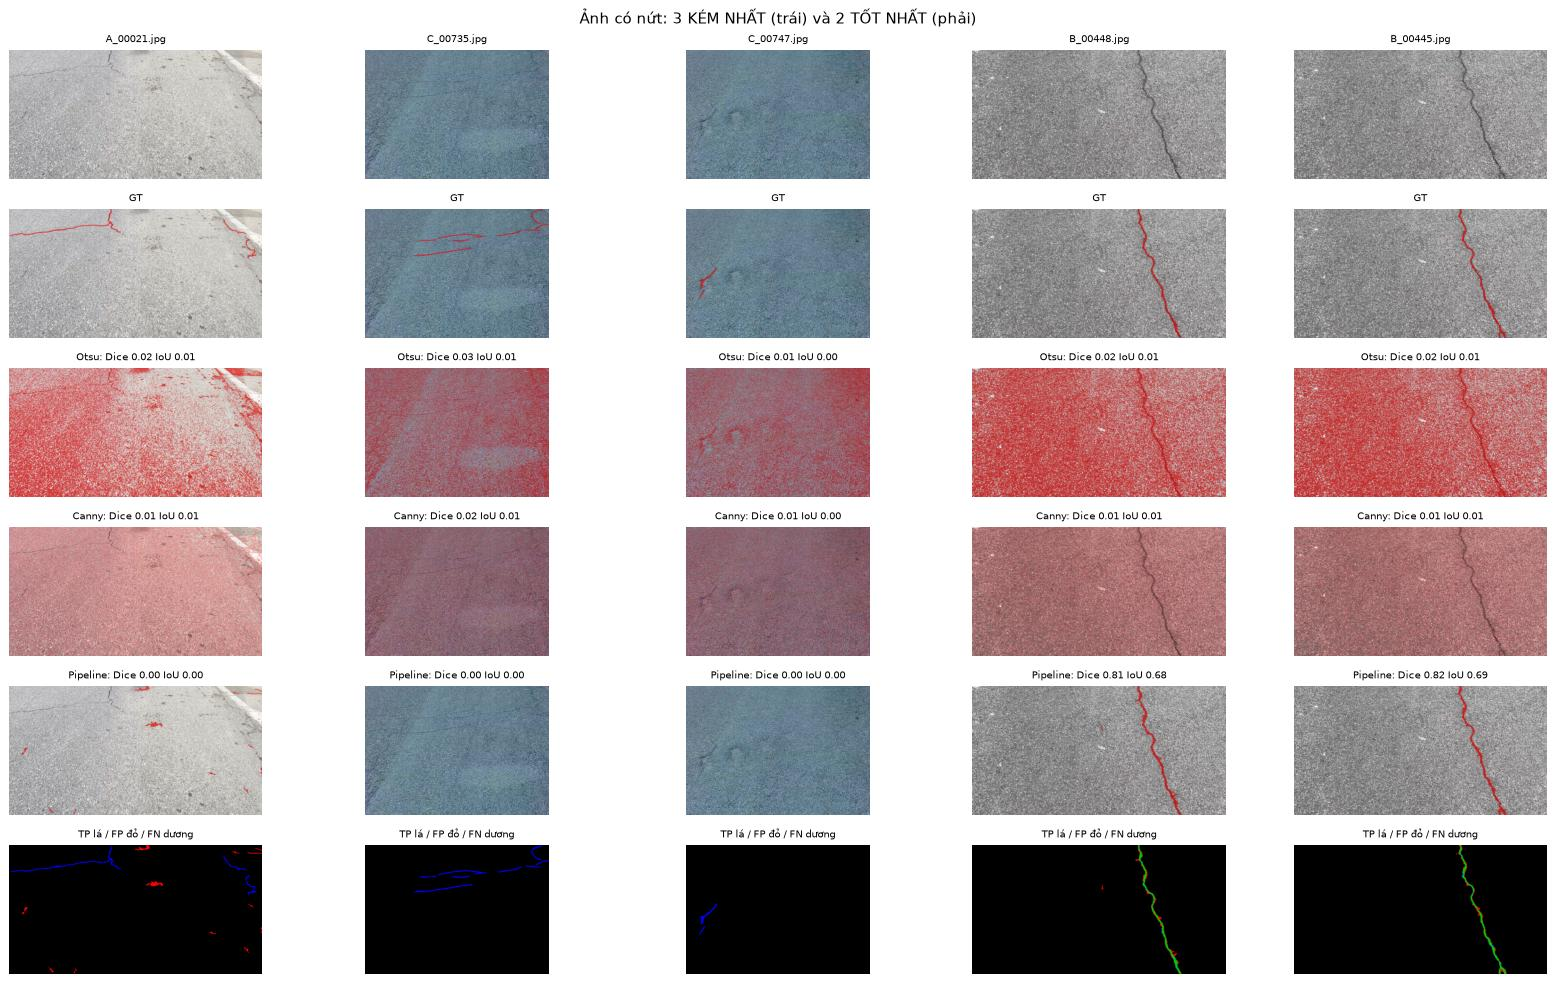

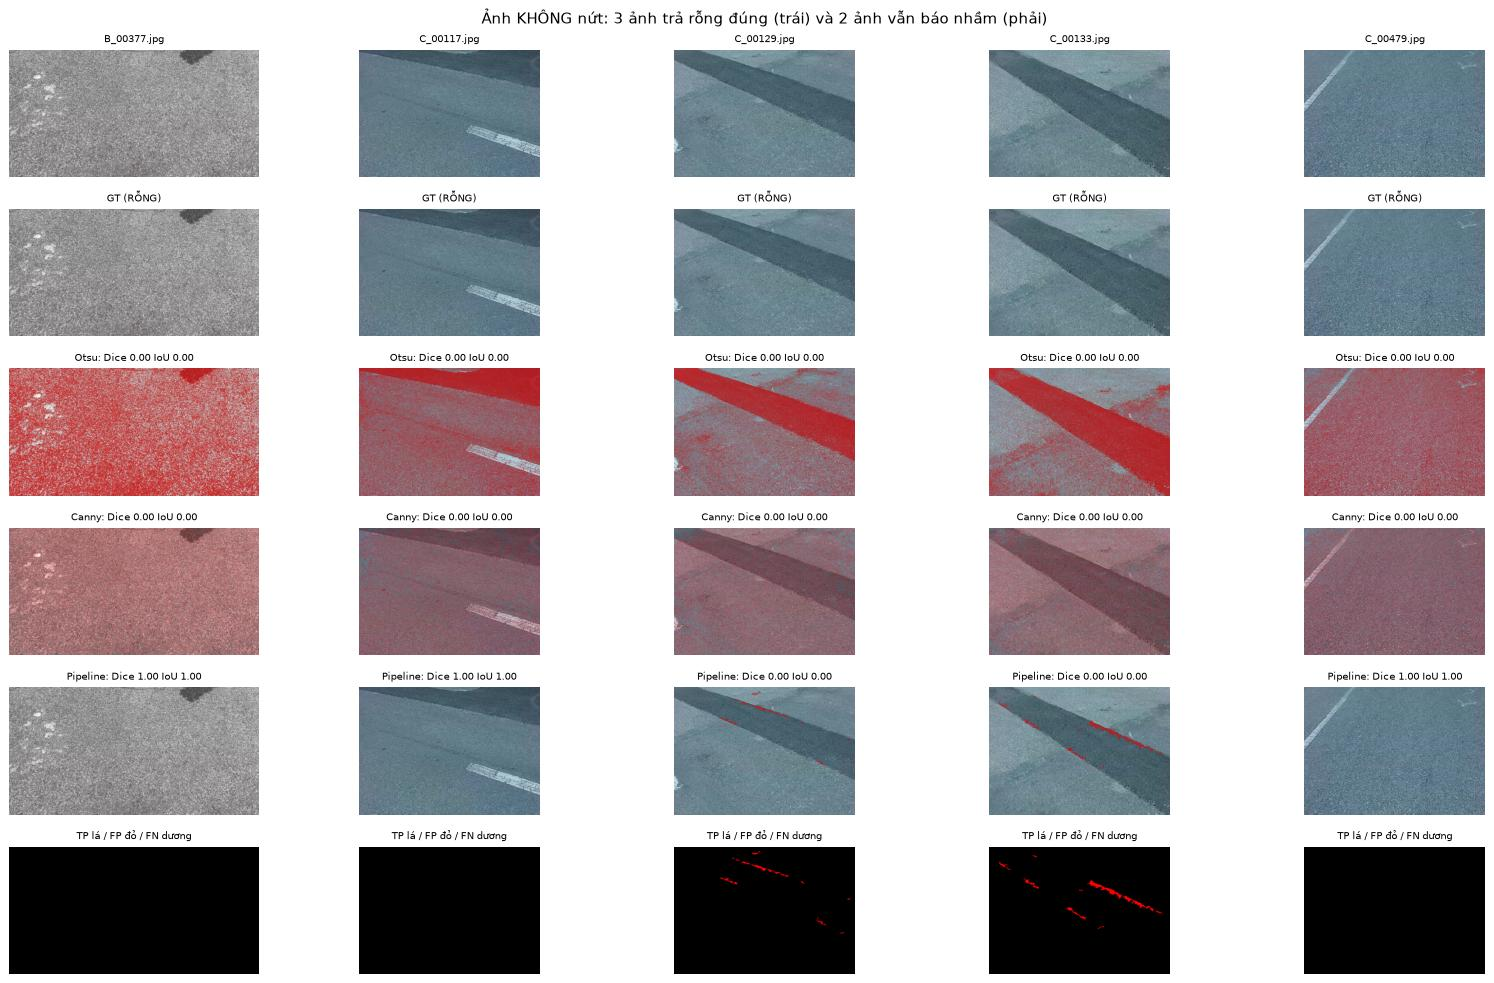

In [27]:
def show_test(ids_, title):
    rows_ = [("Ảnh gốc", None), ("GT", None), ("Otsu", "Đối chứng: Otsu"), ("Canny", "Đối chứng: Canny"),
             ("Pipeline", MAIN), ("Bản đồ lỗi", MAIN)]
    fig, ax = plt.subplots(len(rows_), len(ids_), figsize=(3.6 * len(ids_), 1.75 * len(rows_) + 0.6))
    for j, sid in enumerate(ids_):
        img, gt = read_pair("test", sid)
        for i, (lab, name) in enumerate(rows_):
            if lab == "Ảnh gốc":
                vis, t = small(img), f"{sid}.jpg"
            elif lab == "GT":
                vis, t = small(overlay_red(img, gt)), "GT" + (" (RỖNG)" if not gt.any() else "")
            else:
                pr = METHODS[name](img); sc = scores(pr, gt)
                vis = small(error_map(pr, gt), nearest=True) if lab == "Bản đồ lỗi" else small(overlay_red(img, pr))
                t = "TP lá / FP đỏ / FN dương" if lab == "Bản đồ lỗi" else f"{lab}: Dice {sc['dice']:.2f} IoU {sc['iou']:.2f}"
            ax[i, j].imshow(rgb(vis)); ax[i, j].set_title(t, fontsize=8); ax[i, j].axis("off")
    fig.suptitle(title, fontsize=12); plt.tight_layout(); plt.show()

r_ = np.random.default_rng(SEED)
pick_ = lambda g, n: list(r_.choice([s for s in TEST_IDS if s[0] == g], n, replace=False))
show_test(sorted(pick_("A", 1) + pick_("B", 2) + pick_("C", 2)), "5 ảnh test ngẫu nhiên (1 A, 2 B, 2 C)")
d = PER_IMAGE[(PER_IMAGE.phương_pháp == MAIN) & PER_IMAGE.gt_pos].sort_values("dice")
show_test(list(d.id.head(3)) + list(d.id.tail(2)), "Ảnh có nứt: 3 KÉM NHẤT (trái) và 2 TỐT NHẤT (phải)")
e = PER_IMAGE[(PER_IMAGE.phương_pháp == MAIN) & ~PER_IMAGE.gt_pos]
show_test(sorted(list(e[~e.pred_pos].id.head(3)) + list(e[e.pred_pos].id.head(2))),
          "Ảnh KHÔNG nứt: 3 ảnh trả rỗng đúng (trái) và 2 ảnh vẫn báo nhầm (phải)")

In [28]:
# Lưu 10 ảnh test mẫu (ảnh + GT + kết quả phủ đỏ) vào samples_pcs/
SAMPLE_DIR = os.path.join(ROOT, "samples_pcs")
os.makedirs(SAMPLE_DIR, exist_ok=True)
for f in os.listdir(SAMPLE_DIR):
    os.remove(os.path.join(SAMPLE_DIR, f))
r_ = np.random.default_rng(SEED)
for sid in sorted(list(r_.choice([s for s in TEST_IDS if s[0] == "A"], 2, replace=False)) +
                  list(r_.choice([s for s in TEST_IDS if s[0] == "B"], 4, replace=False)) +
                  list(r_.choice([s for s in TEST_IDS if s[0] == "C"], 4, replace=False))):
    img, gt = read_pair("test", sid)
    cv2.imwrite(os.path.join(SAMPLE_DIR, f"{sid}.jpg"), img)
    cv2.imwrite(os.path.join(SAMPLE_DIR, f"{sid}_gt.png"), u8(gt))
    cv2.imwrite(os.path.join(SAMPLE_DIR, f"{sid}_pred.jpg"), overlay_red(img, pipeline(img, P)))
print(sorted(os.listdir(SAMPLE_DIR)))

['A_00026.jpg', 'A_00026_gt.png', 'A_00026_pred.jpg', 'A_00139.jpg', 'A_00139_gt.png', 'A_00139_pred.jpg', 'B_00038.jpg', 'B_00038_gt.png', 'B_00038_pred.jpg', 'B_00283.jpg', 'B_00283_gt.png', 'B_00283_pred.jpg', 'B_00536.jpg', 'B_00536_gt.png', 'B_00536_pred.jpg', 'B_00647.jpg', 'B_00647_gt.png', 'B_00647_pred.jpg', 'C_01223.jpg', 'C_01223_gt.png', 'C_01223_pred.jpg', 'C_01662.jpg', 'C_01662_gt.png', 'C_01662_pred.jpg', 'C_01697.jpg', 'C_01697_gt.png', 'C_01697_pred.jpg', 'C_02275.jpg', 'C_02275_gt.png', 'C_02275_pred.jpg']


---
# Thảo luận và kết luận

### Kết quả trên tập test (231 ảnh, trong đó 45 ảnh không nứt)

| Phương pháp | Dice | IoU | Dice ảnh nứt | Dice gộp | IoU gộp | Ảnh lành trả rỗng đúng | Ảnh nứt bị trả rỗng |
|---|---|---|---|---|---|---|---|
| Đối chứng: Otsu | 0.024 | 0.012 | 0.030 | 0.027 | 0.014 | 0/45 | 0 |
| Đối chứng: Canny | 0.018 | 0.009 | 0.022 | 0.019 | 0.010 | 0/45 | 0 |
| Pipeline – khởi đầu P0 | 0.296 | 0.227 | **0.319** | 0.345 | 0.209 | 9/45 | 32 |
| **Pipeline – đã chọn P** | **0.339** | **0.274** | 0.303 | **0.426** | **0.271** | **22/45** | 45 |

Theo nhóm (Dice theo ảnh; trong ngoặc là Dice trên ảnh có nứt): **A** 0.126 (0.126) · **B** 0.554 (0.548) · **C** 0.231 (0.113).

1. **So với đối chứng:** Otsu và Canny gần như vô dụng (Dice ≤ 0.03). Otsu gán gần một nửa ảnh là vết nứt vì lược đồ lệch lớp; Canny bắt biên của mọi hạt sỏi. Pipeline tốt hơn cả hai trên **62%** ảnh test và bằng trên 10% (chủ yếu là ảnh mà cả hai cùng Dice 0).
2. **Chọn tham số có ích và không khớp quá mức:** Dice test **0.296 → 0.339**, IoU **0.227 → 0.274**, Dice gộp **0.345 → 0.426**. Tune, val và test cho kết quả khớp nhau: 0.32 → 0.36 → 0.34.
3. **Đóng góp của từng bước trên test** (bỏ một bước, giữ P; so với Dice 0.339):

   | Bỏ bước | Dice | Dice ảnh nứt | Ảnh lành đúng | Kết luận |
   |---|---|---|---|---|
   | Bước 4 (hậu xử lý) | 0.214 | 0.265 | 0/45 | Quan trọng nhất |
   | 2.0 (thu nhỏ) | 0.267 | 0.197 | 25/45 | Bắt buộc |
   | 4.4 (quyết định mức ảnh) | 0.274 | 0.329 | 2/45 | +0.065 Dice, nhưng −0.026 Dice ảnh nứt |
   | 2.3 (bù sáng) | 0.283 | 0.206 | 27/45 | Dice ảnh nứt giảm mạnh nhất |
   | 3.3 (biên) | 0.329 | 0.323 | 16/45 | +0.010, nhờ ảnh lành |
   | 3.1 (làm trơn lược đồ) | 0.340 | 0.304 | 22/45 | **Không có tác dụng trên test**, dù có ích trên tune (K5: +0.021) |

4. **Đánh đổi của bước 4.4:** 22/45 ảnh lành được trả rỗng đúng, nhưng **45/186 ảnh có nứt nhỏ bị trả rỗng** (C 30, B 14, A 1). Vì vậy Dice trên ảnh có nứt (0.303) thấp hơn khi bỏ 4.4 (0.329). Dice gộp gần như không đổi (0.426 so với 0.431).
5. **Theo nhóm:** B (ảnh chụp thẳng từ trên xuống, vết nứt rõ) đạt kết quả tốt nhất, khoảng 0.55. A và C (ảnh chụp xiên, có vạch sơn, vỉa hè) khó hơn nhiều.

### Phân tích lỗi (xem bản đồ lỗi ở trên)
* **FN – bỏ sót:** (1) vết nứt **mờ, ở xa** trong ảnh chụp xiên (A, C), độ tối gần bằng nền nên không vượt θ; (2) ảnh có vết nứt nhỏ bị 4.4 trả rỗng; (3) GT tô **cả bề rộng** vết nứt, còn D chỉ lấy phần lõi tối nhất nên mặt nạ dự đoán hẹp hơn GT.
* **FP – báo nhầm:** **vạch sơn bị nứt hoặc mòn**, mép vỉa hè, nắp cống, khe nối mặt đường, vết dầu dài. Chúng đều tối, dài và có biên, đúng như mô tả vết nứt mà pipeline dùng, nên các bước dựa trên cường độ và hình dạng không phân biệt được.
* **Ảnh lành bị báo nhầm (23/45):** khe nối hoặc vệt tối dài tạo mặt nạ lớn hơn 0.3% ảnh.

### Hạn chế và hướng cải thiện (vẫn trong phạm vi xử lý ảnh cổ điển)
* Bước 4.4 dùng **một đặc trưng đơn giản** (AUC 0.72), nên đổi một loại lỗi lấy loại kia. Có thể kết hợp nhiều đặc trưng vùng.
* Ngưỡng θ **toàn cục trong mỗi ảnh**. Ảnh chụp xiên có chi tiết giảm dần theo khoảng cách, nên cần ngưỡng cục bộ (chia ảnh thành khối).
* Tham số **chung cho cả ba nhóm** ảnh; nhóm A (13 ảnh test) bị thiệt nhất.

### Tổng kết kiến thức theo chương
| Chương | Kiến thức | Bước |
|---|---|---|
| C2 | Lấy mẫu lại (INTER_AREA, láng giềng gần nhất), lượng tử hóa | 2.0, 3.1 |
| C3 | Lọc trung vị (khử nhiễu, ước lượng nền), lọc Gauss (so sánh), biến đổi điểm (ảnh tỉ số) | 2.2, 2.3 |
| C4 | RGB → xám | 1, 2.1 |
| C5 | Làm trơn lược đồ, ngưỡng tam giác, Otsu, Sobel, Canny (đối chứng), các độ đo | 3.1–3.3, 5 |
| C7 | Giãn, đóng, mở (so sánh), thành phần liên thông, diện tích, độ dãn, quyết định mức ảnh | 3.3, 4.1–4.4 |
| C9 | Nguồn dữ liệu, nhãn nhị phân, train/val/test, tránh rò rỉ | 1 |